# H&M — Phân tích khám phá dữ liệu (EDA)

Notebook EDA cho bộ **H&M Personalized Fashion Recommendations** (`hm_v1`) — dữ liệu phục vụ chương *Dữ liệu và giao thức đánh giá* của luận văn.
Chạy được **cục bộ** (đọc `data/hm/`) và trên **Kaggle** (đọc Dataset `hm-dataset-filled`), không cần GPU; toàn bộ chạy trong vài phút.

**Ba nguồn dữ liệu, ba "độ phủ" khác nhau** — mọi phần dưới đây ghi rõ đang dùng nguồn nào:

| Nguồn | File | Phủ | Dùng để |
|---|---|---|---|
| Catalog | `items.parquet` | 105.542 article, 8 cột metadata | §2 |
| **Toàn cục** | `item_daily_counts.parquet` | **31,8 triệu giao dịch** của mọi khách, gộp theo (item, ngày) | §3, §5 (thời vụ, vòng đời, độ phổ biến) |
| **Mẫu 50k khách** | `train/rerank_train/valid/test.parquet` | ~1,27 triệu giao dịch của 50.000 khách (lấy mẫu phân tầng theo mức hoạt động) | §4, §5 (hành vi khách, mua lại, cold-start) |
| Embedding | `text_embeddings.npy`, `image_embeddings.npy` | 105.542 × 512 (Jina CLIP v2) | §6 |
| Khách hàng (tuỳ chọn) | `customers.csv` gốc của cuộc thi | 1,37 triệu khách | §7 — chỉ chạy nếu có file gốc |

> Số liệu **cấp khách** chỉ có trong mẫu 50k nên chịu thiên lệch lấy mẫu (xem §4.2). Số liệu **cấp item / theo thời gian** nên lấy từ nguồn toàn cục.

## 0. Cấu hình và nạp dữ liệu

In [12]:
from __future__ import annotations

import json
import os
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.ticker import FuncFormatter, MaxNLocator

# ---- Công tắc (đặt biến môi trường trước khi chạy, hoặc sửa tại đây) -----------------------------
RUN_EMBEDDINGS = os.getenv("HM_EDA_EMBEDDINGS", "1") == "1"   # §6 cần ~1 GB RAM
SAVE_FIGS = os.getenv("HM_EDA_SAVE_FIGS", "1") == "1"         # lưu PNG để chèn vào luận văn
SEED = 20260922

pl.Config.set_tbl_rows(40).set_tbl_cols(20).set_fmt_str_lengths(60)


def find_data_dir() -> Path:
    """HM_DATA_DIR -> Kaggle Dataset -> data/hm ở thư mục hiện tại hoặc cha."""
    cands = [Path(os.environ["HM_DATA_DIR"])] if os.getenv("HM_DATA_DIR") else []
    cands.append(Path("/kaggle/input/datasets/hoho0111/hm-dataset-filled"))
    here = Path.cwd().resolve()
    cands += [p / "data" / "hm" for p in (here, *here.parents)]
    for c in cands:
        if (c / "items.parquet").exists():
            return c
    kaggle = Path("/kaggle/input")
    if kaggle.exists():
        hit = next(kaggle.rglob("items.parquet"), None)
        if hit is not None:
            return hit.parent
    raise FileNotFoundError("Không thấy items.parquet. Đặt HM_DATA_DIR trỏ tới thư mục dữ liệu H&M.")


DATA = find_data_dir()
ON_KAGGLE = str(DATA).startswith("/kaggle")
OUT = Path(os.getenv("HM_EDA_OUT", "/kaggle/working/hm_eda" if ON_KAGGLE else str(DATA.parent / "artifacts" / "hm" / "eda")))
if SAVE_FIGS:
    (OUT / "figures").mkdir(parents=True, exist_ok=True)
print("DATA :", DATA)
print("OUT  :", OUT if SAVE_FIGS else "(không lưu hình)")

# ---- Style biểu đồ -------------------------------------------------------------------------------
ACCENT, ACCENT2, GREY = "#2a6fdb", "#e07b39", "#8a8f98"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5, "font.size": 9.5,
})
thousands = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))

FACTS: dict = {}   # gom các con số chính -> eda_facts.json (cuối notebook)


def fact(key: str, value):
    """Ghi một con số vào FACTS (ép về kiểu JSON)."""
    if isinstance(value, (np.integer,)):
        value = int(value)
    elif isinstance(value, (np.floating,)):
        value = float(value)
    FACTS[key] = value
    return value


def show(fig, name: str):
    fig.tight_layout()
    if SAVE_FIGS:
        fig.savefig(OUT / "figures" / f"{name}.png", bbox_inches="tight")
    plt.show()


def hbar(ax, names, values, title, xlabel="", color=ACCENT, top=12, pct_of=None):
    names, values = list(names)[:top], list(values)[:top]
    y = np.arange(len(names))[::-1]
    ax.barh(y, values, color=color, height=0.7)
    ax.set_yticks(y, [str(n)[:28] for n in names])
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.xaxis.set_major_formatter(thousands)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.grid(axis="y", visible=False)
    tot = pct_of if pct_of else None
    for yi, v in zip(y, values):
        ax.text(v, yi, f" {v:,.0f}".replace(",", ".") + (f"  ({100 * v / tot:.1f}%)" if tot else ""), va="center", fontsize=8)
    ax.set_xlim(0, max(values) * 1.28)

DATA : D:\WorkSpace\Work\DATN\data\hm
OUT  : D:\WorkSpace\Work\DATN\data\artifacts\hm\eda


In [13]:
items = pl.read_parquet(DATA / "items.parquet").rename({"item_id": "article_id"})

SPLITS = ["train", "rerank_train", "valid", "test"]
SPLIT_NOTE = {"train": "Train (lịch sử)", "rerank_train": "Selection", "valid": "Valid", "test": "Test"}
tx = pl.concat([pl.read_parquet(DATA / f"{s}.parquet").with_columns(pl.lit(s).alias("split")) for s in SPLITS])

GLOBAL_PATH = Path(os.getenv("HM_GLOBAL_STATS", str(DATA / "item_daily_counts.parquet")))
HAS_GLOBAL = GLOBAL_PATH.exists()
daily = pl.read_parquet(GLOBAL_PATH) if HAS_GLOBAL else None   # article_id, t_dat, n, price_sum

DATA_START = daily["t_dat"].min() if HAS_GLOBAL else tx["t_dat"].min()
DATA_END = daily["t_dat"].max() if HAS_GLOBAL else tx["t_dat"].max()
CUT = {s: tx.filter(pl.col("split") == s)["t_dat"].min() for s in SPLITS[1:]}   # ngày bắt đầu từng cửa sổ đích

print(f"items : {items.shape} | tx mẫu: {tx.shape} | toàn cục: {daily.shape if HAS_GLOBAL else 'KHÔNG CÓ item_daily_counts.parquet -> bỏ §3/§5 toàn cục'}")
print(f"khoảng ngày: {DATA_START} -> {DATA_END} | cửa sổ đích bắt đầu: { {k: str(v) for k, v in CUT.items()} }")
missing = tx.join(items.select("article_id"), on="article_id", how="anti").height
print("giao dịch trong mẫu có article_id không nằm trong catalog:", missing)

items : (105542, 9) | tx mẫu: (1273677, 6) | toàn cục: (7443545, 4)
khoảng ngày: 2018-09-20 -> 2020-09-22 | cửa sổ đích bắt đầu: {'rerank_train': '2020-09-02', 'valid': '2020-09-09', 'test': '2020-09-16'}
giao dịch trong mẫu có article_id không nằm trong catalog: 0


## 1. Tổng quan các file

Kiểm tra nhanh kích thước, schema và tính toàn vẹn trước khi đi vào từng phần.

In [14]:
rows = []
for p in sorted(DATA.glob("*.parquet")):
    lf = pl.scan_parquet(p)
    rows.append({"file": p.name, "dòng": lf.select(pl.len()).collect().item(), "cột": len(lf.collect_schema()), "MB": round(p.stat().st_size / 1e6, 2)})
for p in sorted(DATA.glob("*.npy")):
    a = np.load(p, mmap_mode="r")
    rows.append({"file": p.name, "dòng": a.shape[0], "cột": a.shape[1], "MB": round(p.stat().st_size / 1e6, 2)})
inv = pl.DataFrame(rows)
print(inv)
for name in ("run_config.json", "dataset_manifest.json", "embedding_manifest.json"):
    f = DATA / name
    if f.exists():
        print(f"\n--- {name}\n" + f.read_text(encoding="utf-8")[:600])

print("\nSchema giao dịch (mẫu):", dict(tx.schema))
print("Trùng lặp hoàn toàn (customer, article, ngày, giá, kênh) trong mẫu:", int(tx.drop("split").is_duplicated().sum()), "dòng — H&M ghi mỗi đơn vị hàng một dòng, nên đây là mua nhiều cái cùng loại")

shape: (8, 4)
┌───────────────────────────┬─────────┬─────┬────────┐
│ file                      ┆ dòng    ┆ cột ┆ MB     │
│ ---                       ┆ ---     ┆ --- ┆ ---    │
│ str                       ┆ i64     ┆ i64 ┆ f64    │
╞═══════════════════════════╪═════════╪═════╪════════╡
│ item_daily_counts.parquet ┆ 7443545 ┆ 4   ┆ 39.95  │
│ items.parquet             ┆ 105542  ┆ 9   ┆ 2.57   │
│ rerank_train.parquet      ┆ 10452   ┆ 6   ┆ 0.19   │
│ test.parquet              ┆ 9800    ┆ 6   ┆ 0.17   │
│ train.parquet             ┆ 1242735 ┆ 6   ┆ 8.06   │
│ valid.parquet             ┆ 10690   ┆ 6   ┆ 0.18   │
│ image_embeddings.npy      ┆ 105542  ┆ 512 ┆ 216.15 │
│ text_embeddings.npy       ┆ 105542  ┆ 512 ┆ 216.15 │
└───────────────────────────┴─────────┴─────┴────────┘

--- run_config.json
{
  "dataset": "H&M Personalized Fashion Recommendations",
  "version": "hm_v1",
  "profile": "quick",
  "seed": 20260922,
  "customers": 50000,
  "min_train_events": 3,
  "max_events_per_custome

## 2. Catalog (105.542 article)

`articles.csv` có nhiều cột hơn, nhưng `items.parquet` chỉ giữ 8 cột metadata dùng cho embedding văn bản và luật phục vụ. Phần này trả lời: *catalog đa dạng đến đâu? Metadata có sạch không? Mô tả sản phẩm dài bao nhiêu?*

### 2.1 Chất lượng metadata và số giá trị khác nhau

In [15]:
cat_cols = ["product_type_name", "product_group_name", "graphical_appearance_name", "colour_group_name", "department_name", "section_name"]
profile = pl.DataFrame({
    "cột": items.columns,
    "null": [items[c].null_count() for c in items.columns],
    "rỗng": [int((items[c].str.strip_chars() == "").sum()) if items[c].dtype == pl.String else 0 for c in items.columns],
    "khác nhau": [items[c].n_unique() for c in items.columns],
}).with_columns((100 * (pl.col("null") + pl.col("rỗng")) / items.height).round(2).alias("thiếu_%"))
print(profile)
fact("catalog_items", items.height)
fact("detail_desc_missing_pct", float(profile.filter(pl.col("cột") == "detail_desc")["thiếu_%"][0]))
for c in cat_cols:
    fact(f"n_{c}", items[c].n_unique())

shape: (9, 5)
┌───────────────────────────┬──────┬──────┬───────────┬─────────┐
│ cột                       ┆ null ┆ rỗng ┆ khác nhau ┆ thiếu_% │
│ ---                       ┆ ---  ┆ ---  ┆ ---       ┆ ---     │
│ str                       ┆ i64  ┆ i64  ┆ i64       ┆ f64     │
╞═══════════════════════════╪══════╪══════╪═══════════╪═════════╡
│ article_id                ┆ 0    ┆ 0    ┆ 105542    ┆ 0.0     │
│ prod_name                 ┆ 0    ┆ 0    ┆ 45875     ┆ 0.0     │
│ product_type_name         ┆ 0    ┆ 0    ┆ 131       ┆ 0.0     │
│ product_group_name        ┆ 0    ┆ 0    ┆ 19        ┆ 0.0     │
│ graphical_appearance_name ┆ 0    ┆ 0    ┆ 30        ┆ 0.0     │
│ colour_group_name         ┆ 0    ┆ 0    ┆ 50        ┆ 0.0     │
│ department_name           ┆ 0    ┆ 0    ┆ 250       ┆ 0.0     │
│ section_name              ┆ 0    ┆ 0    ┆ 56        ┆ 0.0     │
│ detail_desc               ┆ 416  ┆ 0    ┆ 43405     ┆ 0.39    │
└───────────────────────────┴──────┴──────┴───────────┴───────

### 2.2 Phân bố theo nhóm sản phẩm / màu / bộ phận (đếm **article**)

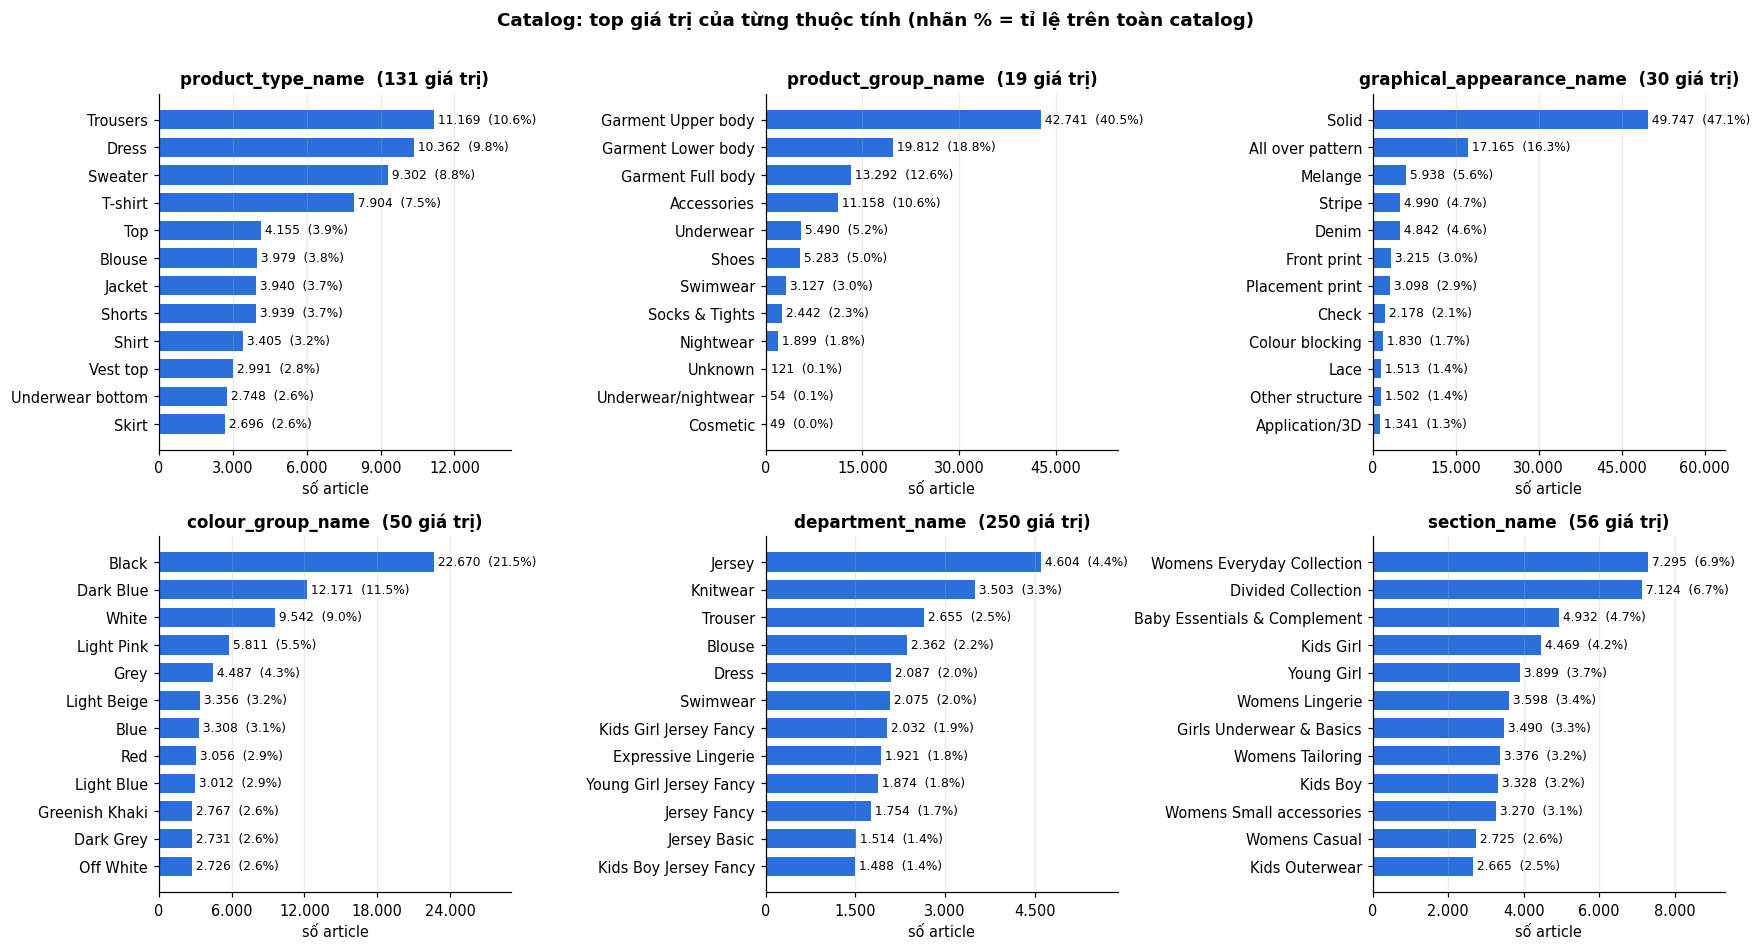

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, c in zip(axes.ravel(), cat_cols):
    vc = items.group_by(c).len().sort("len", descending=True)
    hbar(ax, vc[c], vc["len"], f"{c}  ({vc.height} giá trị)", "số article", top=12, pct_of=items.height)
fig.suptitle("Catalog: top giá trị của từng thuộc tính (nhãn % = tỉ lệ trên toàn catalog)", y=1.01, fontsize=12, fontweight="bold")
show(fig, "02_catalog_categoricals")

### 2.3 Biến thể màu và mô tả sản phẩm

Theo quy ước của cuộc thi, 7 chữ số đầu của `article_id` là *mã sản phẩm* (cùng kiểu dáng), 3 chữ số cuối là *biến thể màu*. Nhiều article chung mô tả → khi đo "độ giống" hay khi sinh ứng viên cần lưu ý các biến thể gần như trùng nhau.

47,224 mã sản phẩm → TB 2.23 biến thể màu/mã; 77.2% article thuộc mã có ≥2 biến thể
79.6% article có mô tả trùng hệt article khác
mô tả (từ): TB 23.9 | trung vị 22 | p95 45 | max 121


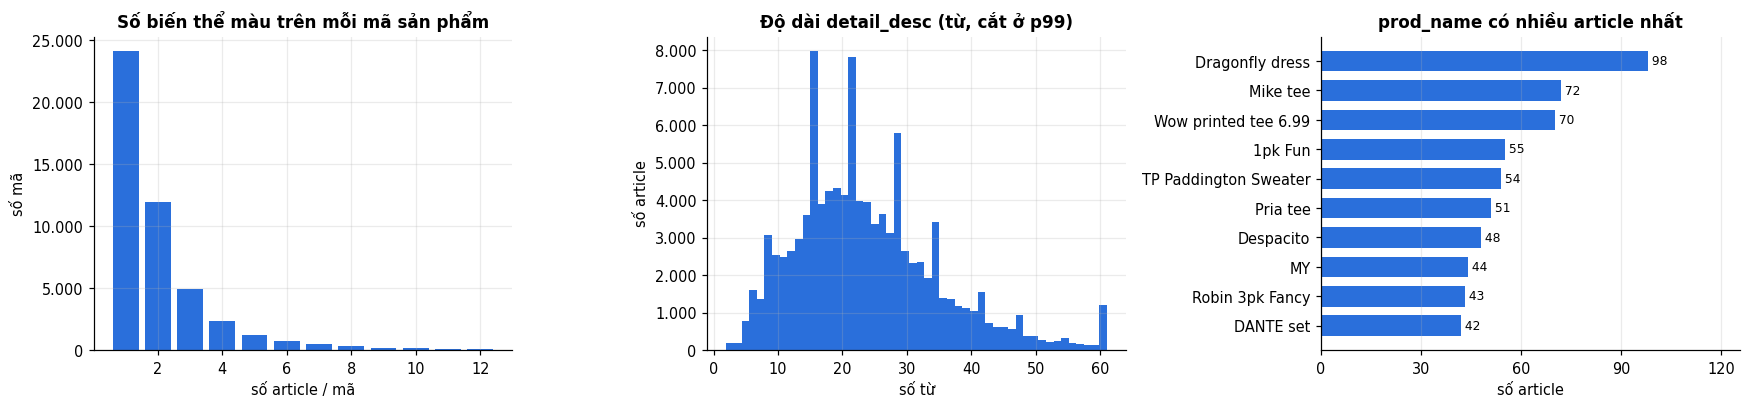

In [17]:
items = items.with_columns(pl.col("article_id").str.slice(0, 7).alias("product_code"))
per_code = items.group_by("product_code").len()
per_name = items.group_by("prod_name").len().sort("len", descending=True)
dup_desc_share = float(items.filter(pl.col("detail_desc").is_not_null())["detail_desc"].is_duplicated().mean())
fact("product_codes", per_code.height)
fact("articles_per_product_code_mean", float(per_code["len"].mean()))
fact("share_articles_in_multi_color_product", float((items.join(per_code.rename({"len": "k"}), on="product_code")["k"] > 1).mean()))
fact("detail_desc_shared_by_multiple_articles_share", dup_desc_share)

desc = items.filter(pl.col("detail_desc").is_not_null()).with_columns(
    pl.col("detail_desc").str.len_chars().alias("chars"), pl.col("detail_desc").str.count_matches(r"\S+").alias("words"))
fact("detail_desc_words_median", float(desc["words"].median()))
fact("detail_desc_words_p95", float(desc["words"].quantile(0.95)))

print(f"{per_code.height:,} mã sản phẩm → TB {per_code['len'].mean():.2f} biến thể màu/mã; {100 * FACTS['share_articles_in_multi_color_product']:.1f}% article thuộc mã có ≥2 biến thể")
print(f"{100 * dup_desc_share:.1f}% article có mô tả trùng hệt article khác")
print("mô tả (từ): TB %.1f | trung vị %d | p95 %d | max %d" % (desc["words"].mean(), desc["words"].median(), desc["words"].quantile(0.95), desc["words"].max()))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
vc = per_code["len"].value_counts().sort("len").filter(pl.col("len") <= 12)
axes[0].bar(vc["len"], vc["count"], color=ACCENT)
axes[0].set(title="Số biến thể màu trên mỗi mã sản phẩm", xlabel="số article / mã", ylabel="số mã")
axes[0].yaxis.set_major_formatter(thousands)
axes[1].hist(desc["words"].clip(upper_bound=int(desc["words"].quantile(0.99))), bins=50, color=ACCENT)
axes[1].set(title="Độ dài detail_desc (từ, cắt ở p99)", xlabel="số từ", ylabel="số article")
axes[1].yaxis.set_major_formatter(thousands)
hbar(axes[2], per_name["prod_name"], per_name["len"], "prod_name có nhiều article nhất", "số article", top=10)
show(fig, "02_catalog_variants_desc")

## 3. Giao dịch toàn cục (31,8 triệu dòng, nguồn `item_daily_counts.parquet`)

Bảng gộp theo (article, ngày) từ **toàn bộ** khách nên không chịu thiên lệch lấy mẫu. Giá trong bộ dữ liệu đã được **chuẩn hoá/ẩn danh** bởi H&M (≈ 0,01–0,5), chỉ so sánh tương đối, không có đơn vị tiền tệ.

### 3.1 Khối lượng theo thời gian và tính thời vụ

31,788,324 giao dịch / 734 ngày (2018-09-20 → 2020-09-22) | TB 43,308/ngày | ngày cao nhất 2019-09-28 (198,622)


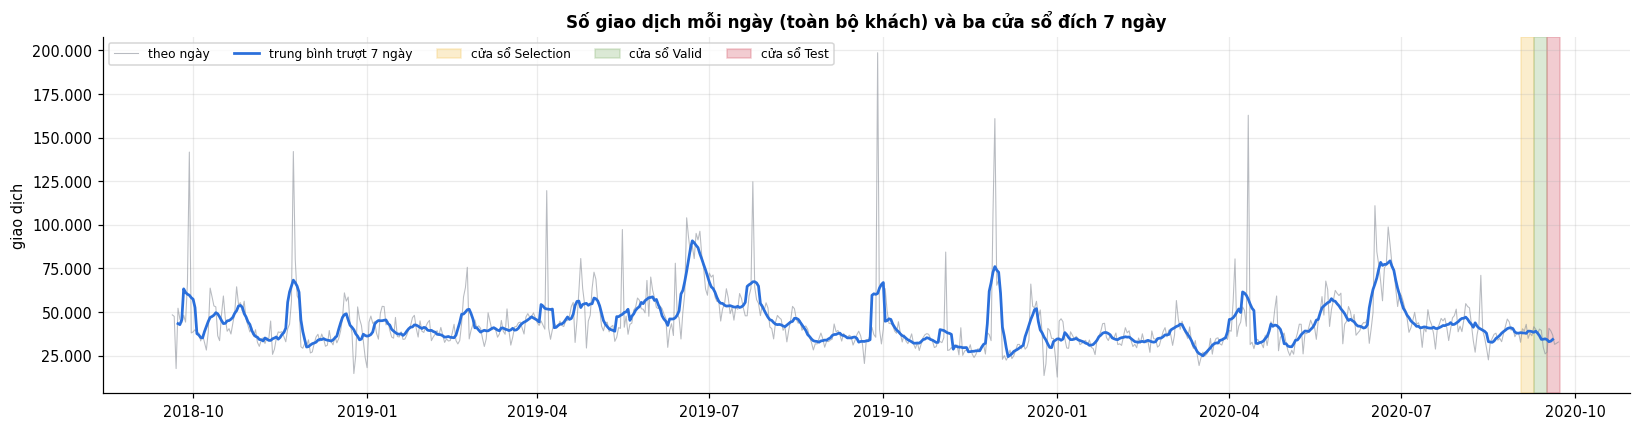

In [18]:
if not HAS_GLOBAL:
    print("Bỏ qua §3: không có item_daily_counts.parquet")
else:
    day = (daily.group_by("t_dat").agg(pl.col("n").sum(), pl.col("price_sum").sum(), pl.col("article_id").n_unique().alias("active_items"))
           .sort("t_dat"))
    fact("transactions_total", int(day["n"].sum()))
    fact("days", day.height)
    fact("transactions_per_day_mean", float(day["n"].mean()))
    print(f"{day['n'].sum():,} giao dịch / {day.height} ngày ({DATA_START} → {DATA_END}) | TB {day['n'].mean():,.0f}/ngày | ngày cao nhất {day.sort('n')[-1]['t_dat'][0]} ({day['n'].max():,})")

    dates, n = day["t_dat"].to_numpy(), day["n"].to_numpy().astype(float)
    ma7 = np.convolve(n, np.ones(7) / 7, mode="same")
    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(dates, n, color=GREY, lw=0.7, alpha=0.6, label="theo ngày")
    ax.plot(dates[3:-3], ma7[3:-3], color=ACCENT, lw=1.8, label="trung bình trượt 7 ngày")
    for (s, c), col in zip(CUT.items(), ("#f2c14e", "#7fb069", "#d1495b")):
        end = {"rerank_train": CUT["valid"], "valid": CUT["test"], "test": DATA_END + timedelta(days=1)}[s]
        ax.axvspan(np.datetime64(c), np.datetime64(end), color=col, alpha=0.28, label=f"cửa sổ {SPLIT_NOTE[s]}")
    ax.set(title="Số giao dịch mỗi ngày (toàn bộ khách) và ba cửa sổ đích 7 ngày", ylabel="giao dịch")
    ax.yaxis.set_major_formatter(thousands)
    ax.legend(ncol=5, fontsize=8, loc="upper left")
    show(fig, "03_daily_volume")

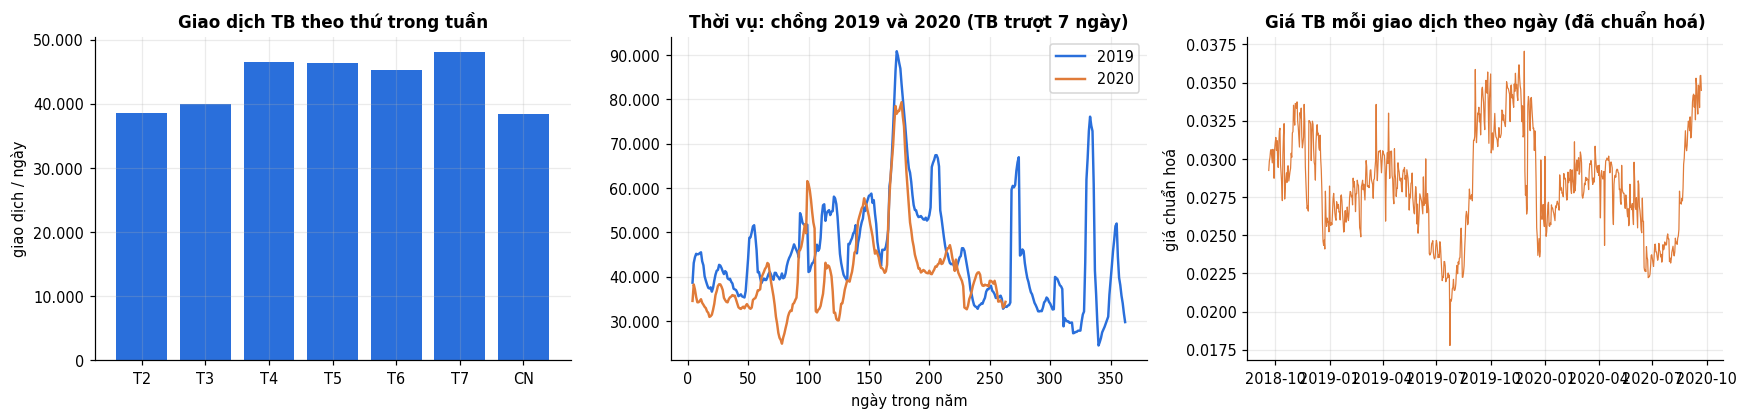

Đọc hình giữa: hai năm lặp lại cùng hình dạng (đỉnh cuối tháng 6 ≈ ngày 175; đỉnh cuối tháng 11 ≈ ngày 330 ở 2019) → thời vụ là tín hiệu thật; các cột nhọn một ngày trong §3.1 là đợt khuyến mãi.


In [19]:
if HAS_GLOBAL:
    # (a) thứ trong tuần, (b) chồng các năm theo ngày trong năm, (c) khách/giá TB theo ngày
    dow = day.with_columns(pl.col("t_dat").dt.weekday().alias("dow")).group_by("dow").agg(pl.col("n").mean()).sort("dow")
    fact("weekday_peak", int(dow.sort("n")[-1]["dow"][0]))
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
    names = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
    axes[0].bar(names, dow["n"], color=ACCENT)
    axes[0].set(title="Giao dịch TB theo thứ trong tuần", ylabel="giao dịch / ngày")
    axes[0].yaxis.set_major_formatter(thousands)

    for yr, col in ((2019, ACCENT), (2020, ACCENT2)):
        sub = day.filter(pl.col("t_dat").dt.year() == yr)
        v = sub["n"].to_numpy().astype(float)
        sm = np.convolve(v, np.ones(7) / 7, mode="same")
        axes[1].plot(sub["t_dat"].dt.ordinal_day().to_numpy()[3:-3], sm[3:-3], color=col, lw=1.6, label=str(yr))
    axes[1].set(title="Thời vụ: chồng 2019 và 2020 (TB trượt 7 ngày)", xlabel="ngày trong năm")
    axes[1].yaxis.set_major_formatter(thousands)
    axes[1].legend()

    avg_price = (day["price_sum"] / day["n"]).to_numpy()
    axes[2].plot(dates, avg_price, color=ACCENT2, lw=0.8)
    axes[2].set(title="Giá TB mỗi giao dịch theo ngày (đã chuẩn hoá)", ylabel="giá chuẩn hoá")
    show(fig, "03_weekday_season_price")
    print("Đọc hình giữa: hai năm lặp lại cùng hình dạng (đỉnh cuối tháng 6 ≈ ngày 175; đỉnh cuối tháng 11 ≈ ngày 330 ở 2019) → thời vụ là tín hiệu thật; các cột nhọn một ngày trong §3.1 là đợt khuyến mãi.")

### 3.2 Ai đang bán? Số item hoạt động mỗi tuần so với cả catalog

TB 20,978 item có bán/tuần = 19.9% catalog | 995 item (0.94%) không có giao dịch nào trong toàn bộ dữ liệu


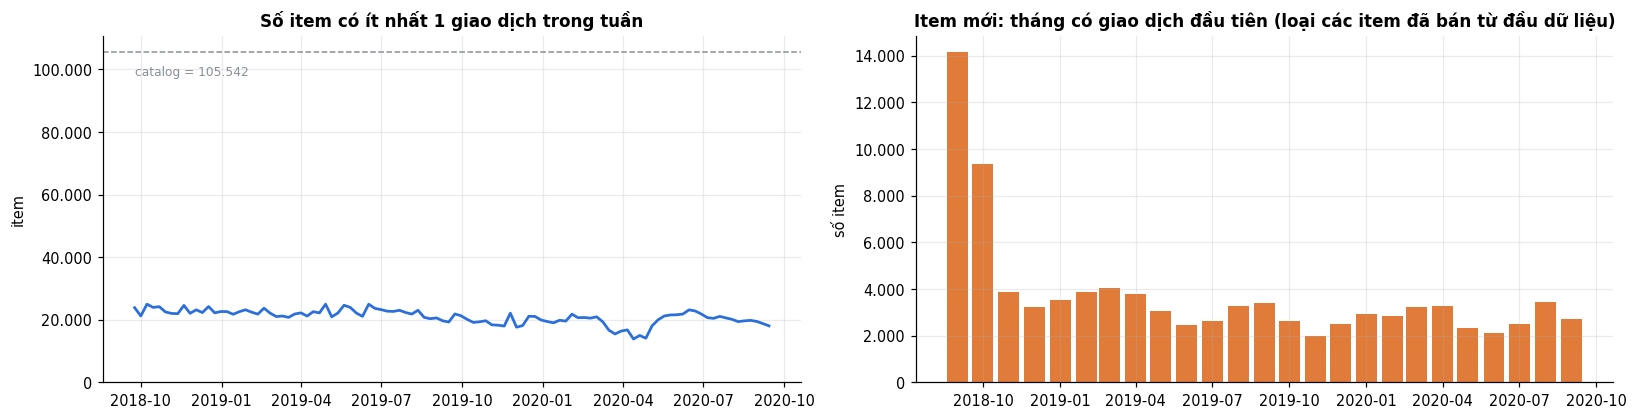

In [20]:
if HAS_GLOBAL:
    weekly = (daily.group_by(pl.col("t_dat").dt.truncate("1w").alias("week"))
              .agg(pl.col("article_id").n_unique().alias("active"), pl.col("n").sum()).sort("week"))
    weekly = weekly.filter((pl.col("week") >= DATA_START) & (pl.col("week") + timedelta(days=6) <= DATA_END))   # bỏ tuần dở
    fact("active_items_per_week_mean", float(weekly["active"].mean()))
    fact("active_items_per_week_share_of_catalog", float(weekly["active"].mean() / items.height))

    istat = daily.group_by("article_id").agg(
        total=pl.col("n").sum(), first_seen=pl.col("t_dat").min(), last_seen=pl.col("t_dat").max(),
        active_days=pl.len(), price_sum=pl.col("price_sum").sum())
    never_sold = items.join(istat.select("article_id"), on="article_id", how="anti").height
    fact("items_never_sold", never_sold)
    fact("items_never_sold_pct", 100 * never_sold / items.height)
    print(f"TB {weekly['active'].mean():,.0f} item có bán/tuần = {100 * weekly['active'].mean() / items.height:.1f}% catalog | "
          f"{never_sold:,} item ({100 * never_sold / items.height:.2f}%) không có giao dịch nào trong toàn bộ dữ liệu")

    fig, axes = plt.subplots(1, 2, figsize=(15, 3.9))
    axes[0].plot(weekly["week"], weekly["active"], color=ACCENT, lw=1.8)
    axes[0].axhline(items.height, color=GREY, ls="--", lw=1)
    axes[0].text(weekly["week"][0], items.height * 0.93, f"catalog = {items.height:,}".replace(",", "."), color=GREY, fontsize=8)
    axes[0].set(title="Số item có ít nhất 1 giao dịch trong tuần", ylabel="item", ylim=(0, items.height * 1.05))
    axes[0].yaxis.set_major_formatter(thousands)

    first_m = (istat.filter(pl.col("first_seen") > DATA_START).group_by(pl.col("first_seen").dt.truncate("1mo").alias("month"))
               .len().sort("month"))
    axes[1].bar(first_m["month"], first_m["len"], width=25, color=ACCENT2)
    axes[1].set(title="Item mới: tháng có giao dịch đầu tiên (loại các item đã bán từ đầu dữ liệu)", ylabel="số item")
    axes[1].yaxis.set_major_formatter(thousands)
    show(fig, "03_active_items_new_items")

### 3.3 Độ phổ biến: đuôi dài

Chuẩn bị cho câu hỏi "popularity là baseline mạnh hay yếu" và "bao nhiêu item đáng để đưa vào ứng viên".

Gini độ phổ biến = 0.761 | {'top 1% item': '18.7% doanh số', 'top 5% item': '44.3% doanh số', 'top 10% item': '61.0% doanh số', 'top 20% item': '79.3% doanh số'}
tỉ lệ item có ≥1 / ≥10 / ≥100 giao dịch: ['99.1%', '78.9%', '42.3%']


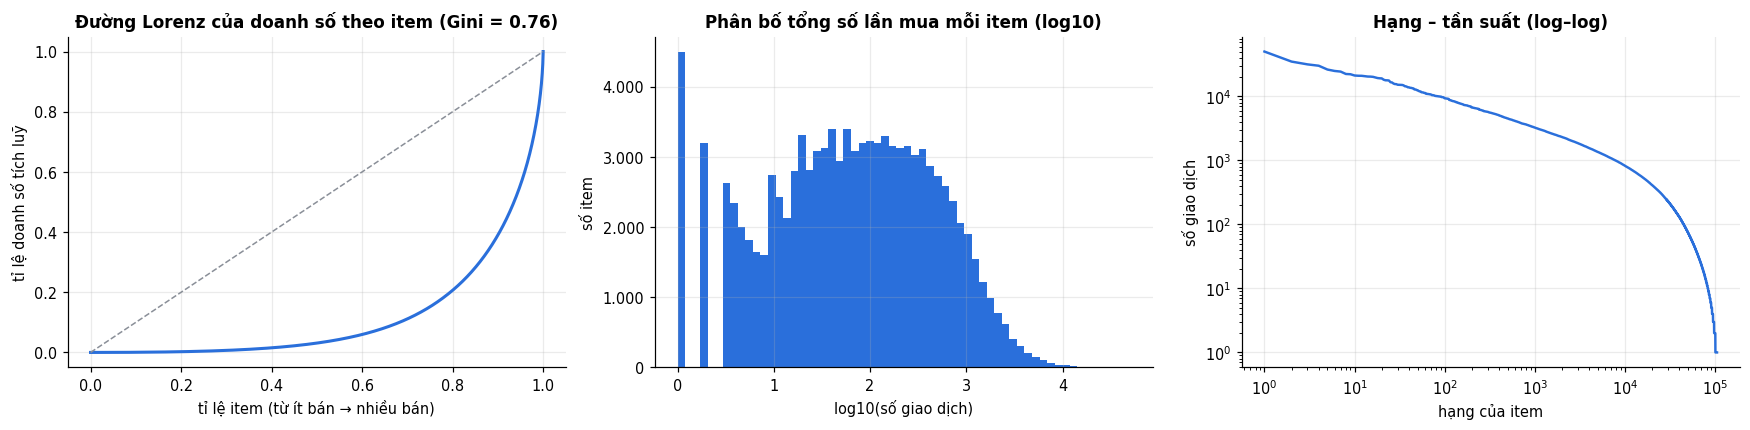

In [21]:
if HAS_GLOBAL:
    cnt = (items.select("article_id").join(istat.select("article_id", "total"), on="article_id", how="left")
           .with_columns(pl.col("total").fill_null(0))["total"].to_numpy().astype(np.float64))
    srt = np.sort(cnt)
    cum = np.concatenate([[0], np.cumsum(srt)]) / srt.sum()
    x = np.linspace(0, 1, len(cum))
    gini = float(1 - 2 * np.sum((cum[:-1] + cum[1:]) / 2 * np.diff(x)))
    fact("popularity_gini", gini)
    desc_sorted = srt[::-1]
    shares = {}
    for pct in (1, 5, 10, 20):
        k = int(round(len(desc_sorted) * pct / 100))
        shares[pct] = float(desc_sorted[:k].sum() / srt.sum())
        fact(f"top_{pct}pct_items_sales_share", shares[pct])
    for thr in (1, 10, 100):
        fact(f"items_with_ge_{thr}_sales_pct", float(100 * np.mean(cnt >= thr)))
    print("Gini độ phổ biến =", round(gini, 3), "|", {f"top {k}% item": f"{100 * v:.1f}% doanh số" for k, v in shares.items()})
    print("tỉ lệ item có ≥1 / ≥10 / ≥100 giao dịch:", [f"{FACTS[f'items_with_ge_{t}_sales_pct']:.1f}%" for t in (1, 10, 100)])

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(x, cum, color=ACCENT, lw=2)
    axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
    axes[0].set(title=f"Đường Lorenz của doanh số theo item (Gini = {gini:.2f})", xlabel="tỉ lệ item (từ ít bán → nhiều bán)", ylabel="tỉ lệ doanh số tích luỹ")
    axes[1].hist(np.log10(cnt[cnt > 0]), bins=60, color=ACCENT)
    axes[1].set(title="Phân bố tổng số lần mua mỗi item (log10)", xlabel="log10(số giao dịch)", ylabel="số item")
    axes[1].yaxis.set_major_formatter(thousands)
    rank = np.arange(1, len(desc_sorted) + 1)
    axes[2].loglog(rank[desc_sorted > 0], desc_sorted[desc_sorted > 0], color=ACCENT, lw=1.6)
    axes[2].set(title="Hạng – tần suất (log–log)", xlabel="hạng của item", ylabel="số giao dịch")
    show(fig, "03_popularity_longtail")

### 3.4 Doanh số theo nhóm sản phẩm: catalog nghiêng về đâu, khách mua gì?

shape: (19, 6)
┌───────────────────────┬──────────┬──────────┬────────────┬───────────┬───────────────────┐
│ product_group_name    ┆ articles ┆ sales    ┆ articles_% ┆ sales_%   ┆ sales_per_article │
│ ---                   ┆ ---      ┆ ---      ┆ ---        ┆ ---       ┆ ---               │
│ str                   ┆ u32      ┆ u32      ┆ f64        ┆ f64       ┆ f64               │
╞═══════════════════════╪══════════╪══════════╪════════════╪═══════════╪═══════════════════╡
│ Garment Upper body    ┆ 42741    ┆ 12552755 ┆ 40.496674  ┆ 39.488571 ┆ 293.693526        │
│ Garment Lower body    ┆ 19812    ┆ 7046054  ┆ 18.771674  ┆ 22.165541 ┆ 355.64577         │
│ Garment Full body     ┆ 13292    ┆ 3552470  ┆ 12.594038  ┆ 11.175393 ┆ 267.263768        │
│ Swimwear              ┆ 3127     ┆ 2579222  ┆ 2.962802   ┆ 8.11374   ┆ 824.823153        │
│ Underwear             ┆ 5490     ┆ 2565858  ┆ 5.201721   ┆ 8.0717    ┆ 467.369399        │
│ Accessories           ┆ 11158    ┆ 1599593  ┆ 10.5720

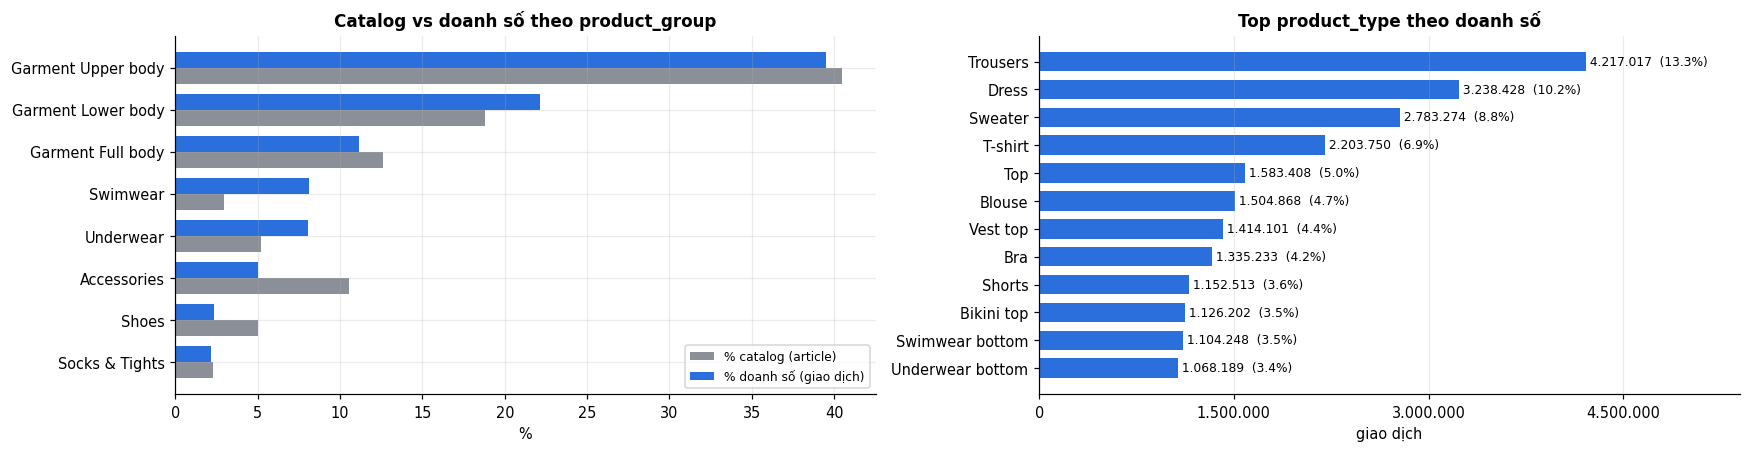

In [22]:
if HAS_GLOBAL:
    meta = items.select("article_id", "product_group_name", "product_type_name", "colour_group_name", "department_name")
    by_group = (meta.join(istat.select("article_id", "total"), on="article_id", how="left").with_columns(pl.col("total").fill_null(0))
                .group_by("product_group_name").agg(articles=pl.len(), sales=pl.col("total").sum())
                .with_columns((100 * pl.col("articles") / pl.col("articles").sum()).alias("articles_%"),
                              (100 * pl.col("sales") / pl.col("sales").sum()).alias("sales_%"),
                              (pl.col("sales") / pl.col("articles")).alias("sales_per_article"))
                .sort("sales", descending=True))
    print(by_group)

    top = by_group.head(8)
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
    w, yy = 0.38, np.arange(top.height)
    axes[0].barh(yy + w / 2, top["articles_%"], w, color=GREY, label="% catalog (article)")
    axes[0].barh(yy - w / 2, top["sales_%"], w, color=ACCENT, label="% doanh số (giao dịch)")
    axes[0].set_yticks(yy, top["product_group_name"])
    axes[0].invert_yaxis()
    axes[0].set(title="Catalog vs doanh số theo product_group", xlabel="%")
    axes[0].legend(fontsize=8)

    for col, color, ax, t in (("product_type_name", ACCENT, axes[1], "Top product_type theo doanh số"),):
        tt = (meta.join(istat.select("article_id", "total"), on="article_id", how="left").with_columns(pl.col("total").fill_null(0))
              .group_by(col).agg(pl.col("total").sum()).sort("total", descending=True))
        hbar(ax, tt[col], tt["total"], t, "giao dịch", color=color, top=12, pct_of=int(tt["total"].sum()))
    show(fig, "03_sales_by_group")

### 3.5 Thời vụ theo loại sản phẩm

Chỉ số thời vụ = (tỉ trọng của loại trong doanh số tháng) / (tỉ trọng trung bình của loại cả giai đoạn). Màu đỏ > 1 là tháng "cao điểm" của loại đó. Chỉ lấy các tháng đủ ngày (10/2018 – 08/2020).

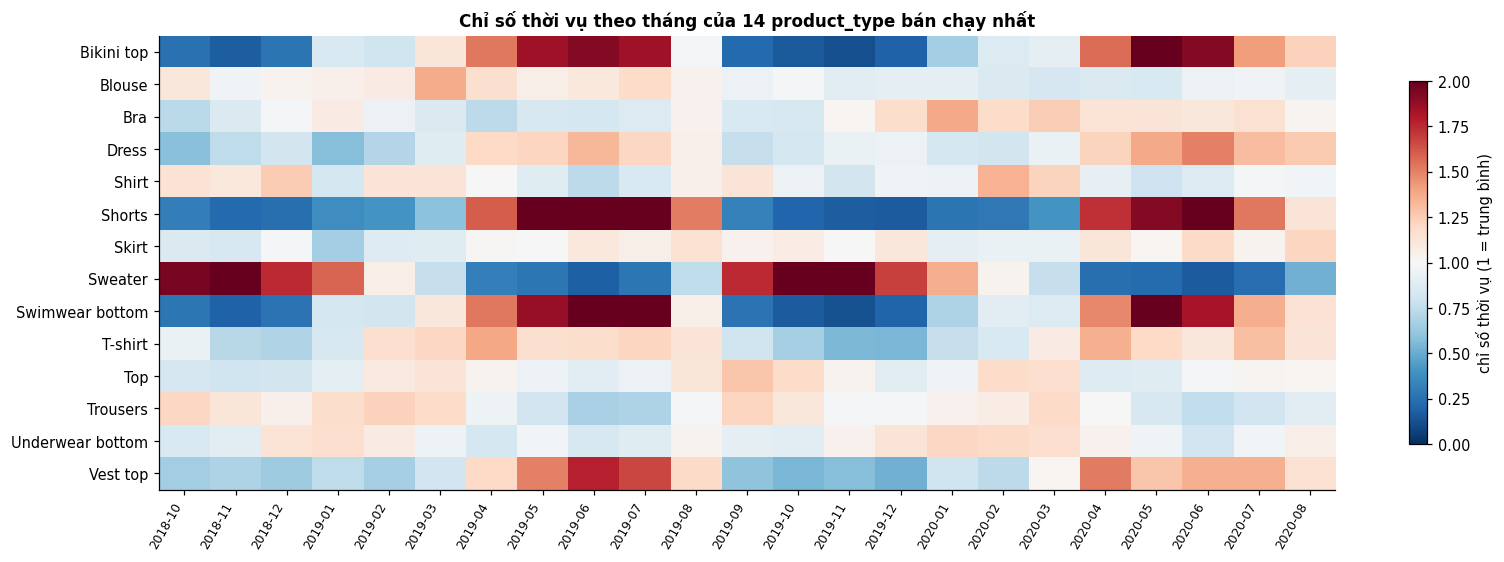

In [23]:
if HAS_GLOBAL:
    top_types = (meta.join(istat.select("article_id", "total"), on="article_id").group_by("product_type_name").agg(pl.col("total").sum())
                 .sort("total", descending=True).head(14)["product_type_name"].to_list())
    monthly = (daily.join(meta.select("article_id", "product_type_name"), on="article_id")
               .group_by(pl.col("t_dat").dt.truncate("1mo").alias("month"), "product_type_name").agg(pl.col("n").sum()))
    mtot = monthly.group_by("month").agg(pl.col("n").sum().alias("tot"))
    first_full = DATA_START if DATA_START.day == 1 else (DATA_START.replace(day=1) + timedelta(days=32)).replace(day=1)
    full_months = [m for m in mtot.sort("month")["month"].to_list() if m >= first_full and (m + timedelta(days=32)).replace(day=1) - timedelta(days=1) <= DATA_END]
    share = (monthly.join(mtot, on="month").filter(pl.col("month").is_in(full_months) & pl.col("product_type_name").is_in(top_types))
             .with_columns((pl.col("n") / pl.col("tot")).alias("share")))
    mat = (share.pivot(on="month", index="product_type_name", values="share").sort("product_type_name"))
    cols = sorted([c for c in mat.columns if c != "product_type_name"], key=lambda c: c)
    M = mat.select(cols).to_numpy().astype(float)
    M = M / np.nanmean(M, axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(15, 5.2))
    im = ax.imshow(M, aspect="auto", cmap="RdBu_r", vmin=0, vmax=2)
    ax.set_yticks(range(len(mat)), mat["product_type_name"])
    ax.set_xticks(range(len(cols)), [c[:7] for c in cols], rotation=60, ha="right", fontsize=8)
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="chỉ số thời vụ (1 = trung bình)", shrink=0.8)
    ax.set_title("Chỉ số thời vụ theo tháng của 14 product_type bán chạy nhất")
    show(fig, "03_seasonality_heatmap")

### 3.6 Vòng đời sản phẩm — item "mới" chiếm bao nhiêu doanh số?

Item có giao dịch đầu tiên **sau** ngày đầu dữ liệu được coi là *ra mắt trong khoảng quan sát*; item bán từ ngày đầu bị cắt trái nên không biết tuổi thật. Đây là cơ sở của khái niệm *cold-start sản phẩm* trong luận văn.

Trong doanh số của item ra mắt trong khoảng quan sát: ≤7 ngày đầu: 6.7% | ≤28 ngày đầu: 24.2% | ≤90 ngày đầu: 58.9% | ≤180 ngày đầu: 81.4%
Tuổi thọ bán (ngày đầu → ngày cuối) của item đã 'đóng' (n=65,585): trung vị 189 ngày, p25 82, p75 345


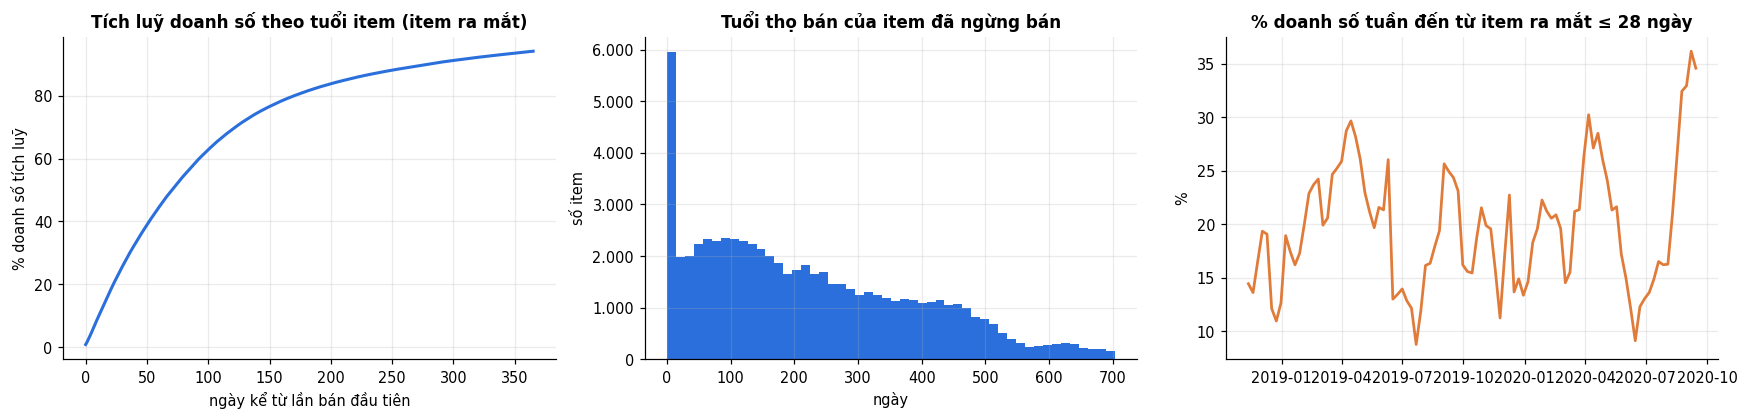

In [24]:
if HAS_GLOBAL:
    fs = istat.select("article_id", "first_seen", "last_seen")
    dd = daily.join(fs, on="article_id").with_columns((pl.col("t_dat") - pl.col("first_seen")).dt.total_days().alias("age"))
    launched = dd.filter(pl.col("first_seen") > DATA_START)
    by_age = launched.group_by("age").agg(pl.col("n").sum()).sort("age")
    cdf = by_age["n"].cum_sum().to_numpy() / by_age["n"].sum()
    ages = by_age["age"].to_numpy()
    for a in (7, 28, 90, 180):
        fact(f"launched_items_sales_within_{a}d_pct", float(100 * cdf[np.searchsorted(ages, a, side='right') - 1]))
    print("Trong doanh số của item ra mắt trong khoảng quan sát: " + " | ".join(f"≤{a} ngày đầu: {FACTS[f'launched_items_sales_within_{a}d_pct']:.1f}%" for a in (7, 28, 90, 180)))

    life = (istat.filter((pl.col("first_seen") > DATA_START) & (pl.col("last_seen") < DATA_END - timedelta(days=28)))
            .with_columns((pl.col("last_seen") - pl.col("first_seen")).dt.total_days().alias("life")))
    fact("lifetime_days_median_closed_items", float(life["life"].median()))
    print(f"Tuổi thọ bán (ngày đầu → ngày cuối) của item đã 'đóng' (n={life.height:,}): trung vị {life['life'].median():.0f} ngày, p25 {life['life'].quantile(.25):.0f}, p75 {life['life'].quantile(.75):.0f}")

    wk_new = (dd.filter(pl.col("t_dat") >= DATA_START + timedelta(days=56))
              .with_columns(((pl.col("first_seen") > DATA_START) & (pl.col("age") <= 28)).alias("new28"))
              .group_by(pl.col("t_dat").dt.truncate("1w").alias("week"))
              .agg((pl.col("n") * pl.col("new28")).sum().alias("new_sales"), pl.col("n").sum().alias("tot")).sort("week"))
    wk_new = wk_new.filter(pl.col("week") + timedelta(days=6) <= DATA_END)
    fact("weekly_share_sales_from_items_launched_within_28d_mean_pct", float(100 * (wk_new["new_sales"] / wk_new["tot"]).mean()))

    fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
    axes[0].plot(ages[ages <= 365], 100 * cdf[ages <= 365], color=ACCENT, lw=2)
    axes[0].set(title="Tích luỹ doanh số theo tuổi item (item ra mắt)", xlabel="ngày kể từ lần bán đầu tiên", ylabel="% doanh số tích luỹ")
    axes[1].hist(life["life"], bins=50, color=ACCENT)
    axes[1].set(title="Tuổi thọ bán của item đã ngừng bán", xlabel="ngày", ylabel="số item")
    axes[1].yaxis.set_major_formatter(thousands)
    axes[2].plot(wk_new["week"], 100 * wk_new["new_sales"] / wk_new["tot"], color=ACCENT2, lw=1.8)
    axes[2].set(title="% doanh số tuần đến từ item ra mắt ≤ 28 ngày", ylabel="%")
    show(fig, "03_item_lifecycle")

## 4. Mẫu 50.000 khách (`hm_v1`)

### 4.1 Bốn cửa sổ thời gian

In [25]:
win = (tx.group_by("split").agg(
    events=pl.len(), users=pl.col("customer_id").n_unique(), items=pl.col("article_id").n_unique(),
    first_day=pl.col("t_dat").min(), last_day=pl.col("t_dat").max())
    .with_columns(pl.col("split").replace_strict({s: i for i, s in enumerate(SPLITS)}).alias("_o")).sort("_o").drop("_o")
    .with_columns((pl.col("events") / pl.col("users")).round(2).alias("events/user")))
print(win)
for r in win.to_dicts():
    fact(f"split_{r['split']}_events", r["events"]); fact(f"split_{r['split']}_users", r["users"]); fact(f"split_{r['split']}_items", r["items"])
fact("sample_users", tx["customer_id"].n_unique())

if HAS_GLOBAL:
    share_sample = tx.height / FACTS["transactions_total"]
    fact("sample_share_of_all_transactions", share_sample)
    print(f"\nMẫu giữ {tx.height:,} / {FACTS['transactions_total']:,} giao dịch = {100 * share_sample:.2f}% (nhưng 50.000 / 1,37 triệu khách ≈ 3,6% khách)")

shape: (4, 7)
┌──────────────┬─────────┬───────┬───────┬────────────┬────────────┬─────────────┐
│ split        ┆ events  ┆ users ┆ items ┆ first_day  ┆ last_day   ┆ events/user │
│ ---          ┆ ---     ┆ ---   ┆ ---   ┆ ---        ┆ ---        ┆ ---         │
│ str          ┆ u32     ┆ u32   ┆ u32   ┆ date       ┆ date       ┆ f64         │
╞══════════════╪═════════╪═══════╪═══════╪════════════╪════════════╪═════════════╡
│ train        ┆ 1242735 ┆ 50000 ┆ 71357 ┆ 2018-09-20 ┆ 2020-09-01 ┆ 24.85       │
│ rerank_train ┆ 10452   ┆ 3063  ┆ 4569  ┆ 2020-09-02 ┆ 2020-09-08 ┆ 3.41        │
│ valid        ┆ 10690   ┆ 3030  ┆ 4505  ┆ 2020-09-09 ┆ 2020-09-15 ┆ 3.53        │
│ test         ┆ 9800    ┆ 2799  ┆ 4200  ┆ 2020-09-16 ┆ 2020-09-22 ┆ 3.5         │
└──────────────┴─────────┴───────┴───────┴────────────┴────────────┴─────────────┘

Mẫu giữ 1,273,677 / 31,788,324 giao dịch = 4.01% (nhưng 50.000 / 1,37 triệu khách ≈ 3,6% khách)


### 4.2 Mẫu có đại diện cho toàn bộ không?

Mẫu lấy phân tầng theo mức hoạt động (§ `00_hm_data_preparation`), nên **hành vi cấp khách** có thể lệch so với toàn bộ. So sánh hình dạng theo thời gian và cơ cấu nhóm sản phẩm giữa mẫu và nguồn toàn cục.

Tương quan khối lượng theo ngày (TB trượt 7 ngày) mẫu vs toàn cục: r = 0.926


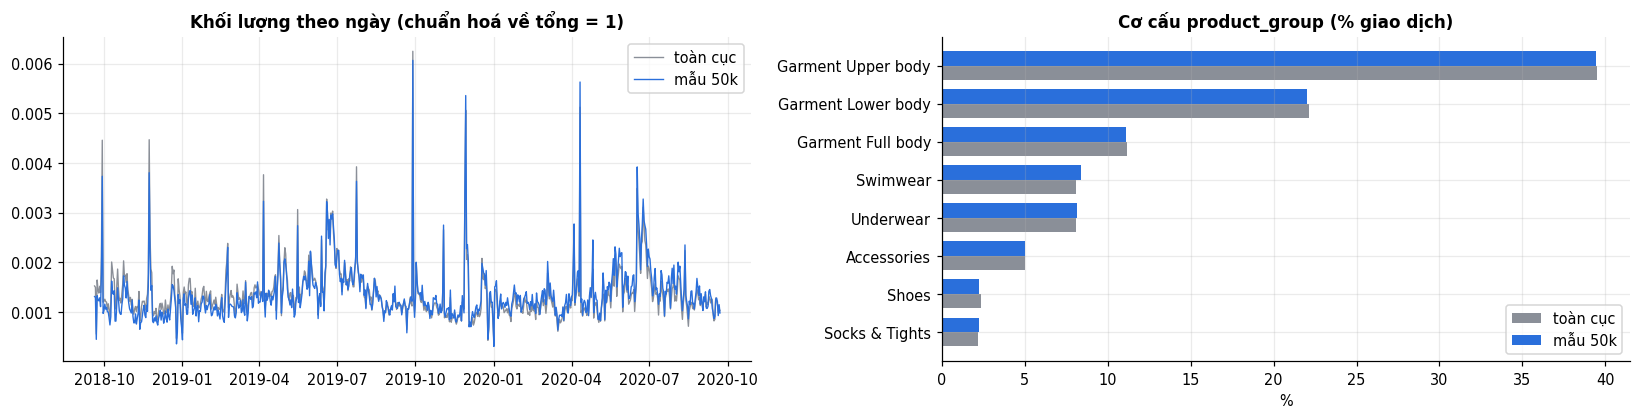

shape: (8, 3)
┌────────────────────┬────────────┬───────┐
│ product_group_name ┆ toàn cục_% ┆ mẫu_% │
│ ---                ┆ ---        ┆ ---   │
│ str                ┆ f64        ┆ f64   │
╞════════════════════╪════════════╪═══════╡
│ Garment Upper body ┆ 39.49      ┆ 39.46 │
│ Garment Lower body ┆ 22.17      ┆ 21.99 │
│ Garment Full body  ┆ 11.18      ┆ 11.1  │
│ Swimwear           ┆ 8.11       ┆ 8.37  │
│ Underwear          ┆ 8.07       ┆ 8.16  │
│ Accessories        ┆ 5.03       ┆ 5.01  │
│ Shoes              ┆ 2.35       ┆ 2.23  │
│ Socks & Tights     ┆ 2.16       ┆ 2.24  │
└────────────────────┴────────────┴───────┘


In [26]:
if HAS_GLOBAL:
    s_day = tx.group_by("t_dat").agg(pl.len().alias("n")).sort("t_dat")
    joined = day.join(s_day, on="t_dat", suffix="_s")
    g = joined["n"].to_numpy().astype(float); s = joined["n_s"].to_numpy().astype(float)
    k = np.ones(7) / 7
    corr = float(np.corrcoef(np.convolve(g, k, "valid"), np.convolve(s, k, "valid"))[0, 1])
    fact("sample_vs_global_daily_volume_corr_7dma", corr)
    print(f"Tương quan khối lượng theo ngày (TB trượt 7 ngày) mẫu vs toàn cục: r = {corr:.3f}")

    g_grp = (daily.join(items.select("article_id", "product_group_name"), on="article_id").group_by("product_group_name").agg(pl.col("n").sum().alias("g")))
    s_grp = (tx.join(items.select("article_id", "product_group_name"), on="article_id").group_by("product_group_name").agg(pl.len().alias("s")))
    cmp = (g_grp.join(s_grp, on="product_group_name", how="full", coalesce=True).fill_null(0)
           .with_columns((100 * pl.col("g") / pl.col("g").sum()).alias("toàn cục_%"), (100 * pl.col("s") / pl.col("s").sum()).alias("mẫu_%"))
           .sort("g", descending=True).head(8))
    fig, axes = plt.subplots(1, 2, figsize=(15, 3.9))
    axes[0].plot(joined["t_dat"], g / g.sum(), color=GREY, lw=0.9, label="toàn cục")
    axes[0].plot(joined["t_dat"], s / s.sum(), color=ACCENT, lw=0.9, label="mẫu 50k")
    axes[0].set(title="Khối lượng theo ngày (chuẩn hoá về tổng = 1)"); axes[0].legend()
    yy = np.arange(cmp.height); w = 0.38
    axes[1].barh(yy + w / 2, cmp["toàn cục_%"], w, color=GREY, label="toàn cục")
    axes[1].barh(yy - w / 2, cmp["mẫu_%"], w, color=ACCENT, label="mẫu 50k")
    axes[1].set_yticks(yy, cmp["product_group_name"]); axes[1].invert_yaxis(); axes[1].legend()
    axes[1].set(title="Cơ cấu product_group (% giao dịch)", xlabel="%")
    show(fig, "04_sample_vs_global")
    print(cmp.select("product_group_name", "toàn cục_%", "mẫu_%").with_columns(pl.col(pl.Float64).round(2)))

### 4.3 Mức hoạt động của khách

Lưu ý: lịch sử cũ bị cắt ở tối đa **100 giao dịch gần nhất** mỗi khách (`max_events_per_customer`) nên đuôi phải của phân bố bị chặn một phần.

shape: (9, 2)
┌─────────────┬──────────┐
│ column      ┆ giá trị  │
│ ---         ┆ ---      │
│ str         ┆ f64      │
╞═════════════╪══════════╡
│ events_p50  ┆ 14.0     │
│ days_p50    ┆ 4.0      │
│ items_p50   ┆ 12.0     │
│ events_p90  ┆ 68.0     │
│ days_p90    ┆ 18.0     │
│ items_p90   ┆ 58.0     │
│ events_mean ┆ 25.47354 │
│ days_mean   ┆ 7.41114  │
│ items_mean  ┆ 22.04632 │
└─────────────┴──────────┘
Khoảng cách giữa hai ngày mua: trung vị 25 ngày, TB 51.0 | số món mỗi ngày mua: TB 3.44, trung vị 2


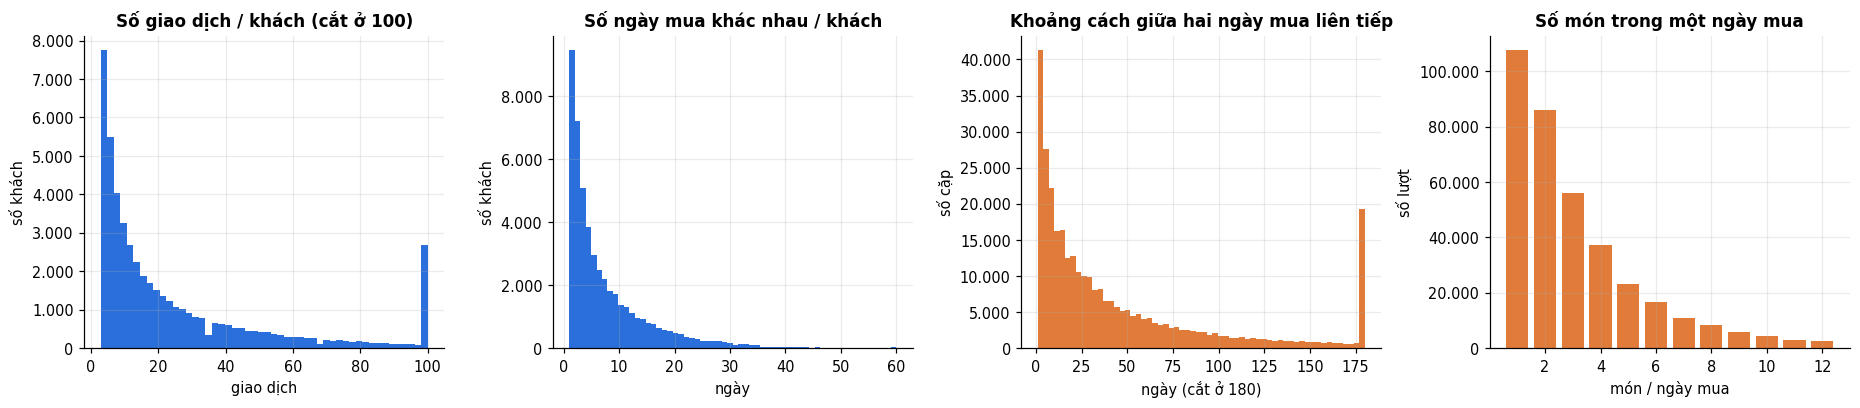

In [27]:
cust = tx.group_by("customer_id").agg(
    events=pl.len(), days=pl.col("t_dat").n_unique(), items=pl.col("article_id").n_unique(),
    first=pl.col("t_dat").min(), last=pl.col("t_dat").max(), spend=pl.col("price").sum())
q = cust.select(pl.col("events", "days", "items").quantile(0.5).name.suffix("_p50"), pl.col("events", "days", "items").quantile(0.9).name.suffix("_p90"),
                pl.col("events", "days", "items").mean().name.suffix("_mean"))
print(q.transpose(include_header=True, column_names=["giá trị"]))
fact("events_per_user_mean", float(cust["events"].mean())); fact("events_per_user_median", float(cust["events"].median()))
fact("purchase_days_per_user_mean", float(cust["days"].mean()))

bins = (cust.with_columns(pl.col("events").log10().floor().clip(0, 4).cast(pl.Int8).alias("bin")).group_by("bin").len().sort("bin"))
labels = {0: "1–9", 1: "10–99", 2: "100–999", 3: "1000+", 4: "1000+"}
gaps = (tx.select("customer_id", "t_dat").unique().sort(["customer_id", "t_dat"])
        .with_columns(pl.col("t_dat").diff().over("customer_id").dt.total_days().alias("gap")).drop_nulls("gap"))
fact("inter_purchase_gap_days_median", float(gaps["gap"].median()))
basket = tx.group_by("customer_id", "t_dat").len()
fact("items_per_purchase_day_mean", float(basket["len"].mean())); fact("items_per_purchase_day_median", float(basket["len"].median()))
print(f"Khoảng cách giữa hai ngày mua: trung vị {gaps['gap'].median():.0f} ngày, TB {gaps['gap'].mean():.1f} | số món mỗi ngày mua: TB {basket['len'].mean():.2f}, trung vị {basket['len'].median():.0f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
axes[0].hist(cust["events"].clip(upper_bound=100), bins=50, color=ACCENT)
axes[0].set(title="Số giao dịch / khách (cắt ở 100)", xlabel="giao dịch", ylabel="số khách"); axes[0].yaxis.set_major_formatter(thousands)
axes[1].hist(cust["days"].clip(upper_bound=60), bins=60, color=ACCENT)
axes[1].set(title="Số ngày mua khác nhau / khách", xlabel="ngày", ylabel="số khách"); axes[1].yaxis.set_major_formatter(thousands)
axes[2].hist(gaps["gap"].clip(upper_bound=180), bins=60, color=ACCENT2)
axes[2].set(title="Khoảng cách giữa hai ngày mua liên tiếp", xlabel="ngày (cắt ở 180)", ylabel="số cặp"); axes[2].yaxis.set_major_formatter(thousands)
bk = basket["len"].value_counts().sort("len").filter(pl.col("len") <= 12)
axes[3].bar(bk["len"], bk["count"], color=ACCENT2)
axes[3].set(title="Số món trong một ngày mua", xlabel="món / ngày mua", ylabel="số lượt"); axes[3].yaxis.set_major_formatter(thousands)
show(fig, "04_customer_activity")

### 4.4 Kênh bán và giá

`sales_channel_id`: 1 = cửa hàng, 2 = online (theo cuộc thi).

shape: (4, 5)
┌──────────────┬────────┬────────┬──────────┬──────────┐
│ split        ┆ 1      ┆ 2      ┆ kênh 1 % ┆ kênh 2 % │
│ ---          ┆ ---    ┆ ---    ┆ ---      ┆ ---      │
│ str          ┆ u32    ┆ u32    ┆ f64      ┆ f64      │
╞══════════════╪════════╪════════╪══════════╪══════════╡
│ train        ┆ 392109 ┆ 850626 ┆ 31.6     ┆ 68.4     │
│ rerank_train ┆ 3344   ┆ 7108   ┆ 32.0     ┆ 68.0     │
│ valid        ┆ 3331   ┆ 7359   ┆ 31.2     ┆ 68.8     │
│ test         ┆ 3020   ┆ 6780   ┆ 30.8     ┆ 69.2     │
└──────────────┴────────┴────────┴──────────┴──────────┘


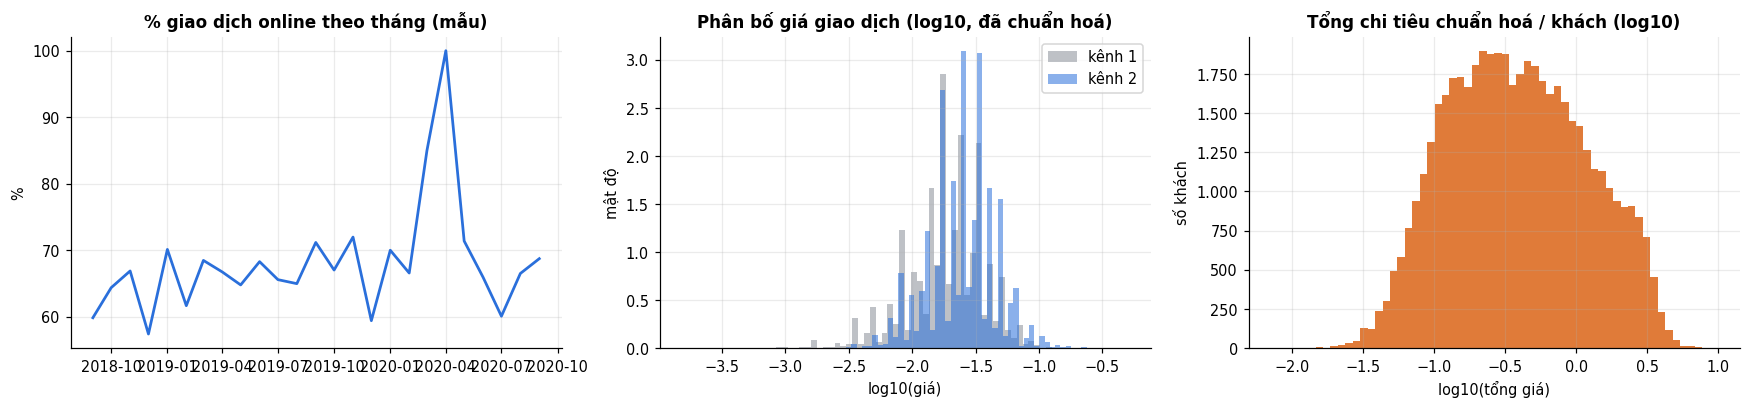

In [28]:
ch = tx.group_by("split", "sales_channel_id").len().pivot(on="sales_channel_id", index="split", values="len").fill_null(0)
ch = ch.with_columns(pl.col("split").replace_strict({s: i for i, s in enumerate(SPLITS)}).alias("_o")).sort("_o").drop("_o")
chan_cols = [c for c in ch.columns if c != "split"]
ch = ch.with_columns([(100 * pl.col(c) / pl.sum_horizontal(chan_cols)).round(1).alias(f"kênh {c} %") for c in chan_cols])
print(ch)
fact("online_channel_share_pct", float(100 * (tx["sales_channel_id"] == 2).mean()))

wk_ch = (tx.group_by(pl.col("t_dat").dt.truncate("1mo").alias("month")).agg((pl.col("sales_channel_id") == 2).mean().alias("online")).sort("month"))
lp = np.log10(tx["price"].to_numpy())
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].plot(wk_ch["month"], 100 * wk_ch["online"], color=ACCENT, lw=1.8)
axes[0].set(title="% giao dịch online theo tháng (mẫu)", ylabel="%")
for chn, col in ((1, GREY), (2, ACCENT)):
    m = (tx["sales_channel_id"] == chn).to_numpy()
    axes[1].hist(lp[m], bins=70, density=True, alpha=0.55, color=col, label=f"kênh {chn}")
axes[1].set(title="Phân bố giá giao dịch (log10, đã chuẩn hoá)", xlabel="log10(giá)", ylabel="mật độ"); axes[1].legend()
cust_spend = cust["spend"].to_numpy()
axes[2].hist(np.log10(cust_spend), bins=60, color=ACCENT2)
axes[2].set(title="Tổng chi tiêu chuẩn hoá / khách (log10)", xlabel="log10(tổng giá)", ylabel="số khách"); axes[2].yaxis.set_major_formatter(thousands)
show(fig, "04_channel_price")

### 4.5 Mua lại (repeat purchase)

Tỉ lệ cặp (khách, item) đã từng xuất hiện trước đó. Đây là lý do luật phục vụ có nhóm "repeat" và lý do đánh giá cho phép item đã mua xuất hiện lại trong top-K.

In [29]:
ordered = tx.sort(["customer_id", "t_dat"])
rep_in_train = (ordered.filter(pl.col("split") == "train")
                .with_columns((pl.int_range(pl.len()).over(["customer_id", "article_id"]) > 0).alias("rep")))
fact("train_event_is_repeat_of_earlier_same_item_pct", float(100 * rep_in_train["rep"].mean()))
print(f"Trong train: {100 * rep_in_train['rep'].mean():.2f}% giao dịch là mua lại đúng item khách đã mua trước đó")

rows = []
hist_splits = []
for s in SPLITS:
    cur = tx.filter(pl.col("split") == s)
    if hist_splits:
        hist = tx.filter(pl.col("split").is_in(hist_splits)).select("customer_id", "article_id").unique()
        pairs = cur.select("customer_id", "article_id").unique()
        rep = pairs.join(hist, on=["customer_id", "article_id"], how="semi").height
        users_hist = cur.select("customer_id").unique().join(hist.select("customer_id").unique(), on="customer_id", how="semi").height
        rows.append({"cửa sổ": s, "cặp (khách,item) khác nhau": pairs.height, "đã mua trước đó": rep, "repeat_%": round(100 * rep / pairs.height, 2),
                     "khách có lịch sử_%": round(100 * users_hist / cur["customer_id"].n_unique(), 1)})
    hist_splits.append(s)
rp = pl.DataFrame(rows)
print(rp)
for r in rp.to_dicts():
    fact(f"repeat_pct_{r['cửa sổ']}", r["repeat_%"])

Trong train: 13.43% giao dịch là mua lại đúng item khách đã mua trước đó
shape: (3, 5)
┌──────────────┬────────────────────────────┬─────────────────┬──────────┬────────────────────┐
│ cửa sổ       ┆ cặp (khách,item) khác nhau ┆ đã mua trước đó ┆ repeat_% ┆ khách có lịch sử_% │
│ ---          ┆ ---                        ┆ ---             ┆ ---      ┆ ---                │
│ str          ┆ i64                        ┆ i64             ┆ f64      ┆ f64                │
╞══════════════╪════════════════════════════╪═════════════════╪══════════╪════════════════════╡
│ rerank_train ┆ 9388                       ┆ 390             ┆ 4.15     ┆ 100.0              │
│ valid        ┆ 9532                       ┆ 410             ┆ 4.3      ┆ 100.0              │
│ test         ┆ 8715                       ┆ 338             ┆ 3.88     ┆ 100.0              │
└──────────────┴────────────────────────────┴─────────────────┴──────────┴────────────────────┘


### 4.6 Cửa sổ đích: ai mua, mua bao nhiêu

Chỉ khách có ≥1 giao dịch trong cửa sổ mới được tính vào metric. Phân bố số item mỗi khách trong cửa sổ cho biết bài toán khó cỡ nào (đích rất ít → Recall@12 bị chặn bởi |T|).

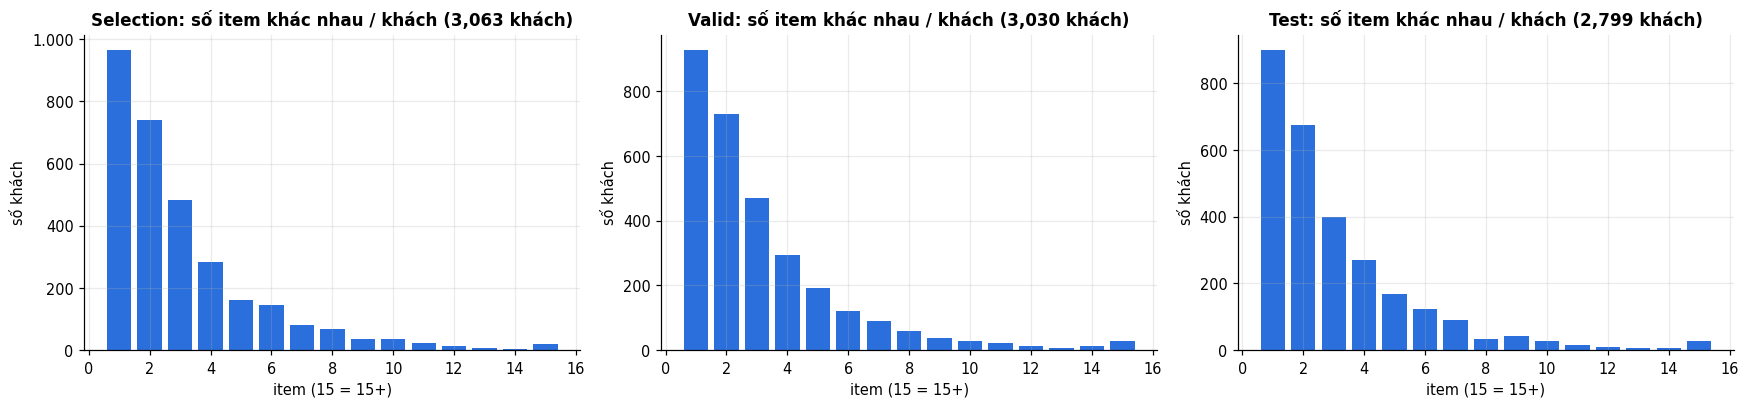

khách mua ở cả valid và test: 554 (19.8% khách test)
Khách active mỗi cửa sổ / 50.000: {'rerank_train': '6.1%', 'valid': '6.1%', 'test': '5.6%'}


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, s in zip(axes, ("rerank_train", "valid", "test")):
    w_ = tx.filter(pl.col("split") == s).group_by("customer_id").agg(pl.col("article_id").n_unique().alias("k"))
    vc = w_["k"].clip(upper_bound=15).value_counts().sort("k")
    ax.bar(vc["k"], vc["count"], color=ACCENT)
    ax.set(title=f"{SPLIT_NOTE[s]}: số item khác nhau / khách ({w_.height:,} khách)", xlabel="item (15 = 15+)", ylabel="số khách")
    ax.yaxis.set_major_formatter(thousands)
    fact(f"window_{s}_items_per_user_mean", float(w_["k"].mean())); fact(f"window_{s}_items_per_user_median", float(w_["k"].median()))
show(fig, "04_window_targets")

v_u = set(tx.filter(pl.col("split") == "valid")["customer_id"].unique().to_list()); t_u = set(tx.filter(pl.col("split") == "test")["customer_id"].unique().to_list())
fact("users_in_both_valid_and_test", len(v_u & t_u))
print(f"khách mua ở cả valid và test: {len(v_u & t_u):,} ({100 * len(v_u & t_u) / len(t_u):.1f}% khách test)")
print("Khách active mỗi cửa sổ / 50.000:", {s: f"{100 * tx.filter(pl.col('split') == s)['customer_id'].n_unique() / 50000:.1f}%" for s in ('rerank_train', 'valid', 'test')})

## 5. Cold-start sản phẩm và độ "tươi" của đích

Với mỗi cửa sổ đích bắt đầu ngày `c`: trong các **sự kiện** của mẫu, bao nhiêu % có item (a) chưa từng có trong `train` của mẫu (cold với tower), (b) chưa có giao dịch nào trước `c` theo thống kê **toàn cục** (never-sold thật sự), (c) đã bán trong N ngày trước `c`?

shape: (3, 8)
┌────────────┬─────────┬────────────┬────────────┬────────────┬────────────┬───────────┬───────────┐
│ cửa sổ     ┆ sự kiện ┆ chưa có    ┆ chưa bán   ┆ bán trong  ┆ bán trong  ┆ bán trong ┆ bán trong │
│ ---        ┆ ---     ┆ trong      ┆ trước c    ┆ 7d trước_% ┆ 14d        ┆ 28d       ┆ 56d       │
│ str        ┆ i64     ┆ train      ┆ (toàn      ┆ ---        ┆ trước_%    ┆ trước_%   ┆ trước_%   │
│            ┆         ┆ mẫu_%      ┆ cục)_%     ┆ f64        ┆ ---        ┆ ---       ┆ ---       │
│            ┆         ┆ ---        ┆ ---        ┆            ┆ f64        ┆ f64       ┆ f64       │
│            ┆         ┆ f64        ┆ f64        ┆            ┆            ┆           ┆           │
╞════════════╪═════════╪════════════╪════════════╪════════════╪════════════╪═══════════╪═══════════╡
│ rerank_tra ┆ 10452   ┆ 11.6       ┆ 6.06       ┆ 91.5       ┆ 92.6       ┆ 93.3      ┆ 93.6      │
│ in         ┆         ┆            ┆            ┆            ┆            ┆ 

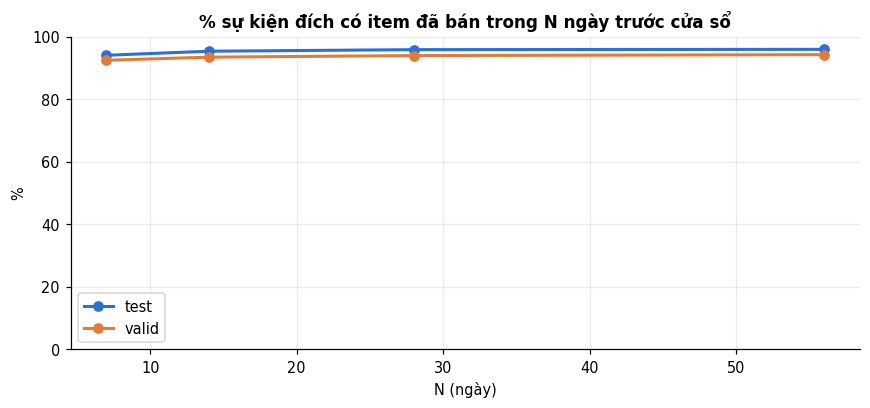

In [31]:
if not HAS_GLOBAL:
    print("Bỏ qua: cần item_daily_counts.parquet")
else:
    train_items = tx.filter(pl.col("split") == "train").select("article_id").unique()
    rows = []
    for s in ("rerank_train", "valid", "test"):
        c = CUT[s]
        w_ = tx.filter(pl.col("split") == s).select("article_id")
        row = {"cửa sổ": s, "sự kiện": w_.height,
               "chưa có trong train mẫu_%": round(100 * w_.join(train_items, on="article_id", how="anti").height / w_.height, 1)}
        ever = daily.filter(pl.col("t_dat") < c).select("article_id").unique()
        row["chưa bán trước c (toàn cục)_%"] = round(100 * w_.join(ever, on="article_id", how="anti").height / w_.height, 2)
        for nd in (7, 14, 28, 56):
            sold = daily.filter((pl.col("t_dat") >= c - timedelta(days=nd)) & (pl.col("t_dat") < c)).select("article_id").unique()
            row[f"bán trong {nd}d trước_%"] = round(100 * w_.join(sold, on="article_id", how="semi").height / w_.height, 1)
        rows.append(row)
    cs = pl.DataFrame(rows)
    print(cs)
    for r in cs.to_dicts():
        for k_, v_ in r.items():
            if k_ not in ("cửa sổ", "sự kiện"):
                fact(f"coldstart_{r['cửa sổ']}_{k_}", v_)

    # Phủ của top-K phổ biến (toàn cục) lên sự kiện đích
    rows = []
    for s in ("valid", "test"):
        c = CUT[s]
        w_ = tx.filter(pl.col("split") == s).select("article_id")
        for label, lo in (("toàn thời gian trước c", None), ("7 ngày trước c", c - timedelta(days=7))):
            base = daily.filter(pl.col("t_dat") < c)
            if lo is not None:
                base = base.filter(pl.col("t_dat") >= lo)
            rank = base.group_by("article_id").agg(pl.col("n").sum()).sort(["n", "article_id"], descending=[True, False])
            row = {"cửa sổ": s, "popularity": label}
            for K in (12, 100, 1000):
                row[f"top-{K}_%"] = round(100 * w_.join(rank.head(K), on="article_id", how="semi").height / w_.height, 2)
            rows.append(row)
    pc = pl.DataFrame(rows)
    print("\nTỉ lệ sự kiện đích nằm trong top-K phổ biến (thống kê toàn cục, KHÔNG phải HitRate theo khách):")
    print(pc)
    for r in pc.to_dicts():
        for K in (12, 100, 1000):
            fact(f"pop_cover_{r['cửa sổ']}_{'all' if 'toàn' in r['popularity'] else 'recent7'}_top{K}", r[f"top-{K}_%"])

    fig, ax = plt.subplots(figsize=(8, 3.8))
    t = cs.filter(pl.col("cửa sổ") == "test").to_dicts()[0]
    ds = [7, 14, 28, 56]
    ax.plot(ds, [t[f"bán trong {d}d trước_%"] for d in ds], marker="o", color=ACCENT, lw=2, label="test")
    v = cs.filter(pl.col("cửa sổ") == "valid").to_dicts()[0]
    ax.plot(ds, [v[f"bán trong {d}d trước_%"] for d in ds], marker="o", color=ACCENT2, lw=2, label="valid")
    ax.set(title="% sự kiện đích có item đã bán trong N ngày trước cửa sổ", xlabel="N (ngày)", ylabel="%", ylim=(0, 100)); ax.legend()
    show(fig, "05_target_freshness")

## 6. Embedding đa phương thức (Jina CLIP v2, 512 chiều)

Kiểm tra chất lượng *dữ liệu đầu vào* của mô hình: độ phủ, độ căn chỉnh văn bản–ảnh, và liệu không gian embedding có tách được nhóm sản phẩm hay không. Hàng `i` của ma trận tương ứng hàng `i` của `items.parquet`.

In [32]:
def find_npy(name: str) -> Path | None:
    for d in (DATA, DATA / "embedding" / "hm", DATA / "embedding", DATA / "serving"):
        if (d / name).exists():
            return d / name
    return None


E = {}
if RUN_EMBEDDINGS:
    tp, ip = find_npy("text_embeddings.npy"), find_npy("image_embeddings.npy")
    if tp and ip:
        E["text"], E["image"] = np.load(tp).astype(np.float32), np.load(ip).astype(np.float32)
        print({k: v.shape for k, v in E.items()}, "| items:", items.height)
        assert all(v.shape[0] == items.height for v in E.values()), "số hàng embedding ≠ số item: kiểm tra thứ tự"
    else:
        print("Không thấy file .npy → bỏ §6")
else:
    print("RUN_EMBEDDINGS=0 → bỏ §6")

{'text': (105542, 512), 'image': (105542, 512)} | items: 105542


vector ảnh = 0: 442 (0.42%) | vector văn bản = 0: 0 | norm TB (khác 0): ảnh 1.000, văn bản 1.000


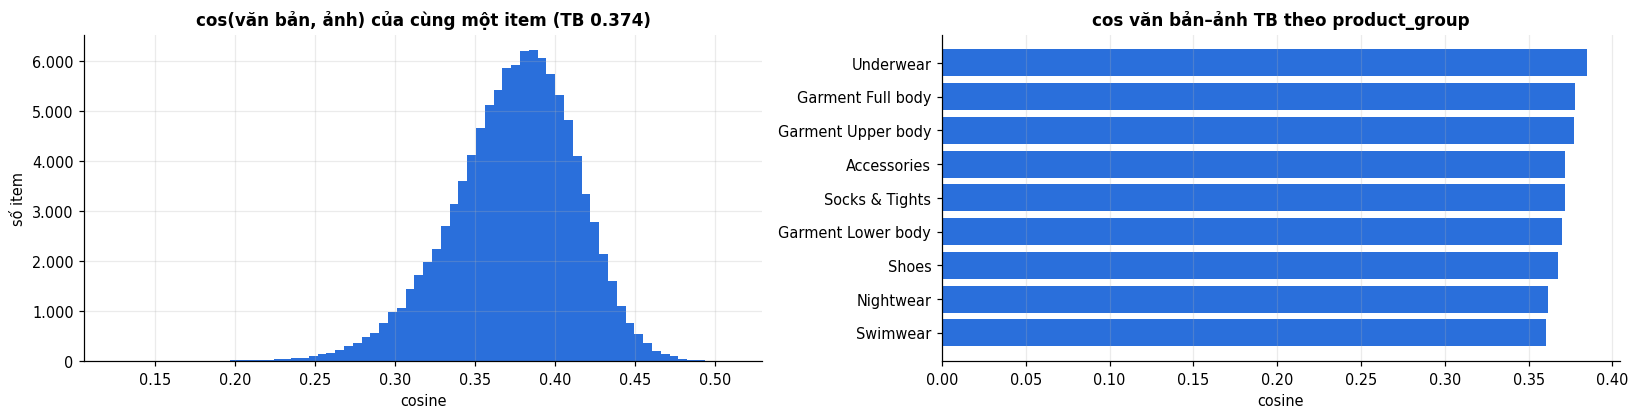

In [33]:
if E:
    nt, ni = np.linalg.norm(E["text"], axis=1), np.linalg.norm(E["image"], axis=1)
    zero_img, zero_txt = ni < 1e-6, nt < 1e-6
    fact("embedding_zero_image_items", int(zero_img.sum())); fact("embedding_zero_text_items", int(zero_txt.sum()))
    fact("embedding_image_coverage_pct", float(100 * (1 - zero_img.mean())))
    print(f"vector ảnh = 0: {zero_img.sum():,} ({100 * zero_img.mean():.2f}%) | vector văn bản = 0: {zero_txt.sum():,} | norm TB (khác 0): ảnh {ni[~zero_img].mean():.3f}, văn bản {nt[~zero_txt].mean():.3f}")

    ok = ~zero_img & ~zero_txt
    cos_ti = np.einsum("ij,ij->i", E["text"][ok], E["image"][ok])
    fact("cos_text_image_mean", float(cos_ti.mean()))
    grp = items["product_group_name"].to_numpy()[ok]
    gdf = pl.DataFrame({"g": grp, "c": cos_ti}).group_by("g").agg(pl.col("c").mean(), pl.len().alias("n")).filter(pl.col("n") >= 200).sort("c")

    fig, axes = plt.subplots(1, 2, figsize=(15, 3.9))
    axes[0].hist(cos_ti, bins=70, color=ACCENT)
    axes[0].set(title=f"cos(văn bản, ảnh) của cùng một item (TB {cos_ti.mean():.3f})", xlabel="cosine", ylabel="số item")
    axes[0].yaxis.set_major_formatter(thousands)
    axes[1].barh(gdf["g"], gdf["c"], color=ACCENT)
    axes[1].set(title="cos văn bản–ảnh TB theo product_group", xlabel="cosine"); axes[1].grid(axis="y", visible=False)
    show(fig, "06_embedding_alignment")

In [34]:
if E:
    # Cross-modal retrieval + độ thuần nhóm của láng giềng: 2.000 truy vấn so với kho 10.000 item (ngẫu nhiên, cố định seed)
    rng = np.random.default_rng(SEED)
    pool = rng.choice(np.flatnonzero(ok), 10_000, replace=False)
    qry = pool[:2_000]
    ptype = items["product_type_name"].to_numpy()
    out = {}
    S_ti = E["text"][qry] @ E["image"][pool].T           # văn bản -> ảnh
    rank = (S_ti > S_ti[np.arange(len(qry)), np.arange(len(qry))][:, None]).sum(1)   # truy vấn i có đích ở cột i
    out["text→image: top-1"], out["text→image: top-10"] = float((rank < 1).mean()), float((rank < 10).mean())
    for name in ("text", "image"):
        S = E[name][qry] @ E[name][pool].T
        S[np.arange(len(qry)), np.arange(len(qry))] = -1                           # bỏ chính nó
        nn = np.argpartition(-S, 10, axis=1)[:, :10]
        same = (ptype[pool][nn] == ptype[qry][:, None]).mean()
        out[f"{name}→{name}: cùng product_type trong top-10"] = float(same)
    for k_, v_ in out.items():
        fact(f"embed_{k_}", v_)
        print(f"{k_:<48}{100 * v_:5.1f}%")
    print("(kho 10.000 item; ngẫu nhiên khoảng 0,1% cho top-10 text→image. Nhiều biến thể màu gần như trùng nhau nên top-1 bị kéo xuống.)")

text→image: top-1                                29.3%
text→image: top-10                               68.5%
text→text: cùng product_type trong top-10        77.7%
image→image: cùng product_type trong top-10      67.0%
(kho 10.000 item; ngẫu nhiên khoảng 0,1% cho top-10 text→image. Nhiều biến thể màu gần như trùng nhau nên top-1 bị kéo xuống.)


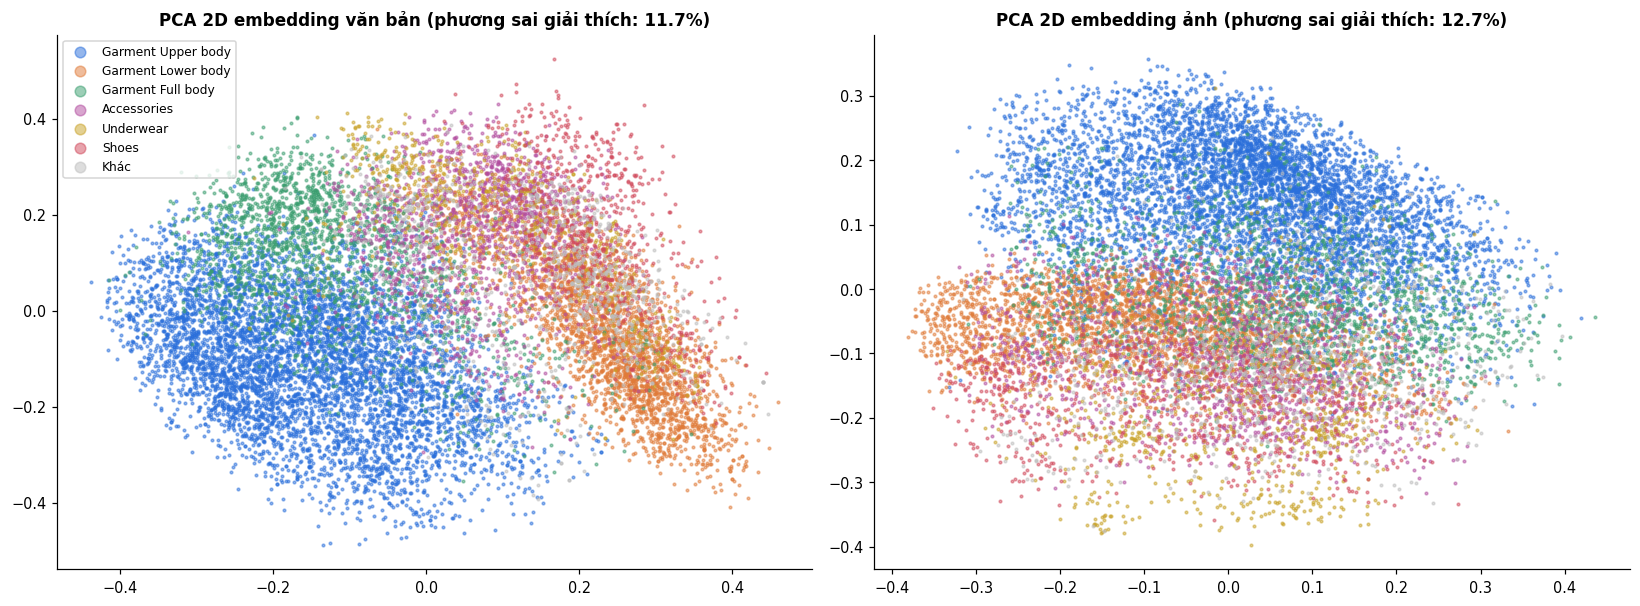

In [35]:
if E:
    # PCA 2D (SVD trên 15.000 item mẫu), tô màu theo product_group
    rng = np.random.default_rng(SEED)
    idx = rng.choice(np.flatnonzero(ok), 15_000, replace=False)
    top_groups = items["product_group_name"].value_counts().sort("count", descending=True).head(6)["product_group_name"].to_list()
    labels = np.array([g if g in top_groups else "Khác" for g in items["product_group_name"].to_numpy()[idx]])
    palette = dict(zip(top_groups + ["Khác"], ["#2a6fdb", "#e07b39", "#3a9e6f", "#b24c9f", "#c9a227", "#d1495b", "#bdbdbd"]))
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
    for ax, name in zip(axes, ("text", "image")):
        X = E[name][idx] - E[name][idx].mean(0)
        _, sv, vt = np.linalg.svd(X, full_matrices=False)
        Z = X @ vt[:2].T
        for g in palette:
            m = labels == g
            ax.scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.5, color=palette[g], label=g, rasterized=True)
        ax.set(title=f"PCA 2D embedding {'văn bản' if name == 'text' else 'ảnh'} (phương sai giải thích: {100 * (sv[:2] ** 2).sum() / (sv ** 2).sum():.1f}%)")
        ax.grid(False)
    axes[0].legend(markerscale=4, fontsize=8, loc="best")
    show(fig, "06_embedding_pca")

## 7. Thuộc tính khách hàng (tuỳ chọn — cần `customers.csv` gốc)

Dữ liệu đã xử lý **không** chứa tuổi, trạng thái thành viên, v.v. (tower chỉ dùng lịch sử mua). Ô dưới chỉ chạy nếu tìm thấy `customers.csv` của cuộc thi (đặt `HM_RAW_DIR` trỏ tới thư mục chứa nó; trên Kaggle tự dò `/kaggle/input`). Nếu không có, phần này được bỏ qua và luận văn nên nêu rõ đây là *hạn chế dữ liệu của mô hình*, không phải của bộ dữ liệu.

In [36]:
def find_raw(name: str) -> Path | None:
    roots = [Path(os.environ["HM_RAW_DIR"])] if os.getenv("HM_RAW_DIR") else []
    roots += [Path("/kaggle/input/h-and-m-personalized-fashion-recommendations"), DATA, DATA.parent, DATA.parent / "raw"]
    for r in roots:
        if (r / name).exists():
            return r / name
    return None


cpath = find_raw("customers.csv")
if cpath is None:
    print("Không có customers.csv → bỏ §7 (xem ghi chú ở trên).")
else:
    cu = pl.read_csv(cpath, schema_overrides={"customer_id": pl.String})
    print(cu.shape, "| cột:", cu.columns)
    prof = pl.DataFrame({"cột": cu.columns, "null_%": [round(100 * cu[c].null_count() / cu.height, 2) for c in cu.columns], "khác nhau": [cu[c].n_unique() for c in cu.columns]})
    print(prof)
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    axes[0].hist(cu["age"].drop_nulls(), bins=np.arange(15, 100, 2), color=ACCENT)
    axes[0].set(title="Phân bố tuổi", xlabel="tuổi", ylabel="số khách"); axes[0].yaxis.set_major_formatter(thousands)
    for ax, c in zip(axes[1:], ("club_member_status", "fashion_news_frequency")):
        vc = cu[c].fill_null("(null)").value_counts().sort("count", descending=True)
        hbar(ax, vc[c], vc["count"], c, "số khách", top=6, pct_of=cu.height)
    show(fig, "07_customers")
    fact("customers_total", cu.height); fact("age_median", float(cu["age"].median())); fact("age_null_pct", float(100 * cu["age"].null_count() / cu.height))
    sampled = tx.select("customer_id").unique()
    cu_s = cu.join(sampled, on="customer_id", how="semi")
    fact("sample_age_median", float(cu_s["age"].median()))
    print(f"tuổi trung vị: toàn bộ {cu['age'].median()} | mẫu 50k {cu_s['age'].median()}")

Không có customers.csv → bỏ §7 (xem ghi chú ở trên).


## 8. Tổng hợp và xuất số liệu

In [37]:
if SAVE_FIGS:
    (OUT).mkdir(parents=True, exist_ok=True)
    (OUT / "eda_facts.json").write_text(json.dumps(FACTS, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Đã lưu {len(FACTS)} con số vào {OUT / 'eda_facts.json'} và {len(list((OUT / 'figures').glob('*.png')))} hình vào {OUT / 'figures'}")
for k_, v_ in FACTS.items():
    print(f"{k_:<62}{v_:,.4f}" if isinstance(v_, float) else f"{k_:<62}{v_:,}" if isinstance(v_, int) else f"{k_:<62}{v_}")

Đã lưu 107 con số vào D:\WorkSpace\Work\DATN\data\artifacts\hm\eda\eda_facts.json và 16 hình vào D:\WorkSpace\Work\DATN\data\artifacts\hm\eda\figures
catalog_items                                                 105,542
detail_desc_missing_pct                                       0.3900
n_product_type_name                                           131
n_product_group_name                                          19
n_graphical_appearance_name                                   30
n_colour_group_name                                           50
n_department_name                                             250
n_section_name                                                56
product_codes                                                 47,224
articles_per_product_code_mean                                2.2349
share_articles_in_multi_color_product                         0.7720
detail_desc_shared_by_multiple_articles_share                 0.7961
detail_desc_words_median                   

## 9. Đọc kết quả vào luận văn

| Phát hiện (xem phần) | Dùng ở đâu | Lý do thiết kế liên quan |
|---|---|---|
| Đuôi dài + Gini cao (§3.3); chỉ ~20% catalog có bán trong một tuần (toàn cục, §3.2; trong mẫu 50k còn ~4–5%) | Mô tả dữ liệu, giải thích baseline popularity yếu / `recent_popularity` mạnh | Luật phục vụ lọc theo "đang bán" (`active_days`) |
| Thời vụ theo ngày/loại (§3.1, §3.5), tuổi thọ item ngắn (§3.6) | Động cơ chia theo **thời gian** thay vì theo khách; hạn chế của ID-embedding | Cửa sổ 7 ngày liên tiếp, thống kê item "không rò rỉ" tại cutoff |
| Item ra mắt ≤ 28 ngày chiếm tỉ trọng đáng kể (§3.6); cold-start trong sự kiện đích (§5) | Cold-start sản phẩm → vai trò của embedding đa phương thức | ID-dropout, kênh cold CLIP |
| Giao dịch/khách thưa, đích 7 ngày chỉ vài item (§4.3, §4.6) | Giải thích vì sao HitRate@12 tuyệt đối thấp; cần bootstrap ghép cặp | Kiểm định theo cụm khách |
| Mua lại: ~4% cặp (khách, item) trong cửa sổ đích đã có trong lịch sử (§4.5) | Nhóm repeat nhỏ nhưng dễ | Cho phép lặp lại item trong top-K |
| Mẫu 50k vs toàn cục (§4.2) | Mục *Hạn chế / mối đe doạ tính hợp lệ* | Thống kê item lấy từ nguồn toàn cục |
| Embedding: độ phủ ảnh, căn chỉnh text–ảnh, độ thuần láng giềng (§6) | Biện minh dùng Jina CLIP v2 đa phương thức | Tower dùng cả text và ảnh |

**Hạn chế cần nêu:** (1) thiên lệch lấy mẫu cấp khách (§4.2); (2) lịch sử cũ bị cắt ở 100 giao dịch; (3) giá đã chuẩn hoá, không có đơn vị tiền; (4) không có tương tác âm tường minh, không có review văn bản; (5) mọi khách test đều có lịch sử → không đo cold-start người dùng.